# Encoder comparison: Transformer / MLP / GLM family

Compares encoders on the same train/valid/test splits as
`preprocess-data-v0j-share.ipynb`.

**Position conditioning (main comparison, 8 models):**
1. **GLM** — `GLM_3DCosineBasis`, position-only (lag 0).
2. **GLM + lags** — time-lagged positions in `[-1, +1] s`.
3. **GLM + lags + kin** — adds speed + velocity-direction bumps + IMU.
4. **GLM + hist** — `GLM_Coupled` with a Pillow spike-history filter `h`.
5. **GLM + coup** — `GLM_Coupled` with coupling filters `l_i` (other neurons' past).
6. **GLM + hist + coup** — both temporal filters.
7. **MLP only** — `Bat_Transformer` with `use_attention=False`.
8. **Transformer** — full `Bat_Transformer` with RoPE attention.

The +hist / +coup / +hist+coup GLMs (Pillow et al. 2008) augment the place-field
stimulus drive with causal log-spaced raised-cosine temporal filters; their
coupling penalty `alpha` is selected jointly with `weight_decay` by Optuna.

**Joint (position, trajectory) conditioning:** the four position-basis GLMs
(`GLM`, `GLM + hist`, `GLM + coup`, `GLM + hist + coup`) are *also* fit with
**trajectory-cluster-specific place fields** — one place-field readout per flight
cluster. Position vs joint conditioning is compared in a dedicated section, with
separate rows per conditioning.

Metrics: per-neuron Poisson FDE and Pearson correlation on the held-out test
set, by flight filter (all / in-domain / OOD).


In [33]:
%load_ext autoreload
%autoreload 2

import os
import sys
from copy import deepcopy
from collections import Counter

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import torch
from torch import nn
from scipy.stats import wilcoxon
from scipy.interpolate import interp1d
from scipy.cluster.hierarchy import linkage, fcluster
from scipy.spatial.distance import squareform
import optuna

sys.path.append(os.path.expanduser('~/Documents/code/digitalbat'))
from digitalbat.datasets.data import bat_data_loader
from digitalbat.datasets.defaults import DEFAULT_SESSION_NAMES, make_data_config
from digitalbat.models.former import Bat_Transformer
from digitalbat.models.former_defaults import (
    DEFAULT_LR, DEFAULT_WEIGHT_DECAY,
    make_model_config, make_model_name, make_trainer_config,
)
from digitalbat.models.glm import (
    GLM_3DCosineBasis, GLM_3DCosineBasis_Kinematics,
    GLM_Coupled, make_log_raised_cosine_basis, make_symmetric_raised_cosine_basis,
    coupling_group_penalty, create_cosine_bumps_torch,
)
from digitalbat.models.layers import ELU1
from digitalbat.training.trainer import bat_former_trainer
from digitalbat.utility.utils import (
    corr, poisson_fde_population, set_random_state,
    bat_palette, parse_bat, wilcoxon_safe, frechet_distance,
    add_significance_bracket, annotate_pvalue_corner,
)

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [34]:
seed = 1
set_random_state(seed)
device = 'cuda'

# Main (position-conditioning) comparison order. The Pillow-style temporal-filter
# GLMs (+hist / +coup / +hist+coup, plus the acausal self-filter) are folded in
# alongside the existing encoders.
MODEL_ORDER = ['GLM', 'GLM + lags', 'GLM + lags + kin',
               'GLM + hist', 'GLM + coup', 'GLM + hist + coup', 'GLM + acausal',
               'MLP only', 'Transformer']

# GLM family that ALSO gets trajectory-cluster-specific place fields ("joint"
# (position, trajectory) conditioning). Only the position-basis GLMs qualify:
# +lags/+lags+kin would need a per-cluster copy of a ~45k-feature design
# (>>100M params), and MLP/Transformer have no explicit place basis (the
# transformer already sees the trajectory through attention).
GLM_JOINT_MODELS = ['GLM', 'GLM + hist', 'GLM + coup', 'GLM + hist + coup',
                    'GLM + acausal']
CONDITIONINGS = ['position', 'joint']

# (model_name, conditioning) pairs that get fit / evaluated.
FIT_SPECS = ([(m, 'position') for m in MODEL_ORDER]
             + [(m, 'joint') for m in GLM_JOINT_MODELS])

# --- Pillow-style temporal-filter bases (history h, coupling l, acausal a) ---
# History is STRICTLY PAST (lags 1..N_LAGS) -- a neuron can't predict its own
# current bin. Coupling INCLUDES lag 0 (the simultaneous bin): using other
# neurons' current-bin spikes is fine since the self-diagonal is masked. The
# acausal self-filter looks BOTH backward and forward (lags -N_LAGS..-1, +1..+N_LAGS)
# on a separate set of SYMMETRIC basis bumps, with lag 0 EXCLUDED so a neuron's
# current bin never predicts itself (past/future bumps carry independent weights).
HIST_N_BASIS = 6     # paper used 10 at 1 ms; we have 0.1 s bins
COUP_N_BASIS = 4     # paper used 4
ACAUSAL_N_BASIS = 6  # bumps PER SIDE -> 2*ACAUSAL_N_BASIS columns over +/- lags
N_LAGS = 10          # window = 10 bins = 1.0 s each side (flights have median ~2.1 s)
BIN_WIDTH = 0.10
hist_basis, hist_lags, _ = make_log_raised_cosine_basis(HIST_N_BASIS, N_LAGS, BIN_WIDTH)
coup_basis, coup_lags, _ = make_log_raised_cosine_basis(COUP_N_BASIS, N_LAGS, BIN_WIDTH,
                                                        include_zero_lag=True)
acausal_basis, acausal_lags, _ = make_symmetric_raised_cosine_basis(
    ACAUSAL_N_BASIS, N_LAGS, BIN_WIDTH)

# --- Trajectory-cluster (joint conditioning) settings ---
CLUSTER_ALPHA = 0.8          # Fréchet single-linkage AFFINITY THRESHOLD (matches decode notebook)
CLUSTER_DS = 7               # trajectory downsample length
MIN_CLUSTER_FLIGHTS = 3      # train clusters with < 3 flights are pooled into 'other'
CLUSTER_MAX_ALPHA = 1.5      # ceiling when bumping alpha to escape a single-cluster fit
UNCLUSTERED = -1

# --- Optuna search for GLM hyperparameters (weight_decay, + alpha for coupled) ---
# Continuous LOG-UNIFORM search (optuna suggest_float(..., log=True)) over the full
# practical range -- not a discrete grid. Widen/narrow the bounds as needed; with a
# very wide range you may want to raise GLM_N_TRIALS for adequate coverage.
GLM_N_TRIALS = 10            # raise toward the decoder notebook's 20 for a finer search
GLM_WD_RANGE = (1e-4, 50.0)  # weight_decay, log-uniform (shared by EVERY GLM)
GLM_ALPHA_RANGE = (1e-4, 1e2)  # coupling group-lasso strength, log-uniform

# --- Checkpoints ---
# DATA_TAG encodes the split-defining data config (max_acceleration / session
# list; see digitalbat/datasets/defaults.make_data_config). It is appended to
# every checkpoint path so that changing the split invalidates stale checkpoints
# and forces a fresh fit -- the shape-only `_ckpt_is_compatible` check below
# cannot detect a split change on its own. Old (pre-split-change) checkpoints
# are left on disk under their previous (untagged / older-tagged) names. Bump
# this string whenever the canonical split changes.
DATA_TAG = '_acc50'

BAT_FORMER_CKPT = make_model_name(seed, DEFAULT_LR, DEFAULT_WEIGHT_DECAY,
                                  out_dir='./out/bat_former', suffix=DATA_TAG)
BAT_FORMER_NOATTN_CKPT = make_model_name(seed, DEFAULT_LR, DEFAULT_WEIGHT_DECAY,
                                         out_dir='./out/bat_former_no_attn', suffix=DATA_TAG)
os.makedirs(os.path.dirname(BAT_FORMER_NOATTN_CKPT), exist_ok=True)
os.makedirs('./out/bat_glm', exist_ok=True)

def ckpt_path(name, cond):
    if name == 'Transformer':
        return BAT_FORMER_CKPT
    if name == 'MLP only':
        return BAT_FORMER_NOATTN_CKPT
    # Every GLM (plain / +lags / +lags+kin / +hist / +coup / +hist+coup / +acausal,
    # position or joint) is tuned via Optuna and saved under one uniform name.
    tag = name.lower().replace(' + ', '_').replace(' ', '_')
    return f'./out/bat_glm/bat_{tag}_{cond}_seed_{seed}_optuna{DATA_TAG}.pth'

CKPT_PATHS = {key: ckpt_path(*key) for key in FIT_SPECS}
for key in FIT_SPECS:
    print(f'  {key[0]:<18} [{key[1]:<8}] -> {CKPT_PATHS[key]}  (exists={os.path.exists(CKPT_PATHS[key])})')

BAT_PALETTE = bat_palette()

  GLM                [position] -> ./out/bat_glm/bat_glm_position_seed_1_optuna_acc50.pth  (exists=False)
  GLM + lags         [position] -> ./out/bat_glm/bat_glm_lags_position_seed_1_optuna_acc50.pth  (exists=False)
  GLM + lags + kin   [position] -> ./out/bat_glm/bat_glm_lags_kin_position_seed_1_optuna_acc50.pth  (exists=False)
  GLM + hist         [position] -> ./out/bat_glm/bat_glm_hist_position_seed_1_optuna_acc50.pth  (exists=True)
  GLM + coup         [position] -> ./out/bat_glm/bat_glm_coup_position_seed_1_optuna_acc50.pth  (exists=True)
  GLM + hist + coup  [position] -> ./out/bat_glm/bat_glm_hist_coup_position_seed_1_optuna_acc50.pth  (exists=True)
  GLM + acausal      [position] -> ./out/bat_glm/bat_glm_acausal_position_seed_1_optuna_acc50.pth  (exists=False)
  MLP only           [position] -> ./out/bat_former_no_attn/bat_former_seed_1_lr_1.00e-02_wd_1.00e-02_acc50.pth  (exists=False)
  Transformer        [position] -> ./out/bat_former/bat_former_seed_1_lr_1.00e-02_wd_1.00e-

## Data loader

Single call to `bat_data_loader` shared by both models so the train/valid/test
splits and the standardization stats are identical.

In [3]:
data_config = make_data_config()
dataloaders, behavior_dim, unit_num_dict, meta_info_dict = bat_data_loader(**data_config)
print(f'Base dataloader: behavior_dim={behavior_dim}, {len(unit_num_dict)} sessions')

# Kinematics dataloader for the `GLM + lags + kin` variant: adds speed,
# head direction (vel_unit), and IMU to the behavior vector
# (dims: 0-2=xyz, 3=speed, 4-6=vel_unit, 7-9=imu_acc, 10-12=imu_gyr).
data_config_kin = {**data_config, 'use_speed_head_dir': True, 'use_IMU_flag': True}
dataloaders_kin, behavior_dim_kin, unit_num_dict_kin, meta_info_dict_kin = bat_data_loader(**data_config_kin)
print(f'Kinematics dataloader: behavior_dim={behavior_dim_kin}')

  Acceleration filter: removed 4/37 flights (peak |acc| > 40 m/s²)
  Acceleration filter: removed 4/136 flights (peak |acc| > 40 m/s²)
  Acceleration filter: removed 14/154 flights (peak |acc| > 40 m/s²)
  Acceleration filter: removed 6/131 flights (peak |acc| > 40 m/s²)
  Acceleration filter: removed 2/79 flights (peak |acc| > 40 m/s²)
  Acceleration filter: removed 2/78 flights (peak |acc| > 40 m/s²)
  Acceleration filter: removed 1/77 flights (peak |acc| > 40 m/s²)
  Acceleration filter: removed 4/82 flights (peak |acc| > 40 m/s²)
  Acceleration filter: removed 1/98 flights (peak |acc| > 40 m/s²)
  Acceleration filter: removed 3/80 flights (peak |acc| > 40 m/s²)
  Acceleration filter: removed 4/112 flights (peak |acc| > 40 m/s²)
  Acceleration filter: removed 2/145 flights (peak |acc| > 40 m/s²)
Base dataloader: behavior_dim=3, 18 sessions
  Acceleration filter: removed 4/37 flights (peak |acc| > 40 m/s²)
  Acceleration filter: removed 4/136 flights (peak |acc| > 40 m/s²)
  Accelera

In [35]:
# Per-(model, conditioning) dataloader routing. Everything uses the base
# position-only loaders except `GLM + lags + kin`, which needs the kinematics
# loaders. Joint conditioning also uses the base loaders -- the cluster id is
# threaded in separately via `flight_cluster`, not through the behavior tensor.
def data_for(name, cond):
    if name == 'GLM + lags + kin':
        return dataloaders_kin, meta_info_dict_kin
    return dataloaders, meta_info_dict


In [36]:
# ---- Train-only trajectory clustering for the JOINT (position, trajectory) GLMs.
#
# Flights are clustered by discrete Fréchet distance between 7-point-downsampled
# 3D trajectories, single-linkage at the AFFINITY THRESHOLD alpha = CLUSTER_ALPHA
# (= 0.8, matching decode-position-comparison.ipynb). Clustering uses TRAIN
# flights only; valid/test flights are assigned to the nearest train flight's
# cluster iff that Fréchet distance <= alpha, else 'other'. Train clusters with
# < MIN_CLUSTER_FLIGHTS (3) flights are pooled into 'other' (id = UNCLUSTERED).
#
# We do NOT mutate `flight_type_index` (that would corrupt the in-domain/OOD
# split, which keys off the loader's original cluster ids). Instead we return a
# {session: {flight_path_index: cluster_id}} map and pass cluster ids to the
# joint models explicitly at train/eval time.
def _downsample_traj(pos_xyz, mask, ds=CLUSTER_DS):
    N = pos_xyz.shape[0]
    out = np.full((N, ds, 3), np.nan)
    for i in range(N):
        L = int(mask[i].sum())
        if L < 2:
            continue
        traj = pos_xyz[i, mask[i]]
        new_idx = np.linspace(0, L - 1, ds)
        for d in range(3):
            out[i, :, d] = interp1d(np.arange(L), traj[:, d])(new_idx)
    return out


def compute_flight_clusters(dataloaders, meta, alpha=CLUSTER_ALPHA):
    flight_cluster, cluster_keys, info = {}, {}, {}
    for sn in dataloaders['train'].keys():
        bm = np.asarray(meta['behavior_mean'][sn]).reshape(-1)
        bs = np.asarray(meta['behavior_std'][sn]).reshape(-1)
        trajs, fpis = {}, {}
        for split in ('train', 'valid', 'test'):
            ds = dataloaders[split][sn].dataset
            pos = (ds.behavior.numpy() * bs + bm)[..., :3]
            trajs[split] = _downsample_traj(pos, ds.mask.numpy().astype(bool))
            fpis[split] = ds.flight_path_index.numpy().astype(int)
        Xtr = trajs['train']
        keep = np.where(~np.isnan(Xtr[:, 0, 0]))[0]
        X, n = Xtr[keep], len(keep)
        mapping = {}
        if n < 2:
            for split in ('train', 'valid', 'test'):
                for f in fpis[split]:
                    mapping[int(f)] = UNCLUSTERED
            flight_cluster[sn], cluster_keys[sn] = mapping, []
            continue
        D = np.zeros((n, n))
        for i in range(n):
            for j in range(i + 1, n):
                D[i, j] = D[j, i] = frechet_distance(X[i], X[j])
        used_alpha = alpha
        while True:
            Z = linkage(squareform(D, checks=False), method='single')
            labels = fcluster(Z, t=used_alpha, criterion='distance').astype(int)
            if len(np.unique(labels)) > 1 or used_alpha >= CLUSTER_MAX_ALPHA:
                break
            used_alpha += 0.1
        counts = Counter(labels)
        major = sorted(int(c) for c, k in counts.items() if k >= MIN_CLUSTER_FLIGHTS)
        majset = set(major)
        for p, gi in enumerate(keep):
            lab = int(labels[p])
            mapping[int(fpis['train'][gi])] = lab if lab in majset else UNCLUSTERED
        for gi in range(Xtr.shape[0]):
            mapping.setdefault(int(fpis['train'][gi]), UNCLUSTERED)
        for split in ('valid', 'test'):
            t = trajs[split]
            for i in range(t.shape[0]):
                f = int(fpis[split][i])
                if np.isnan(t[i, 0, 0]):
                    mapping[f] = UNCLUSTERED
                    continue
                dists = np.array([frechet_distance(t[i], X[j]) for j in range(n)])
                jm = int(np.argmin(dists))
                lab = int(labels[jm])
                mapping[f] = lab if (dists[jm] <= used_alpha and lab in majset) else UNCLUSTERED
        flight_cluster[sn], cluster_keys[sn] = mapping, major
        n_other = sum(1 for v in mapping.values() if v == UNCLUSTERED)
        info[sn] = dict(alpha=used_alpha, n_train=n, n_major=len(major),
                        n_flights=len(mapping), n_other=n_other)
    return flight_cluster, cluster_keys, info


flight_cluster, cluster_keys_by_session, cluster_info = compute_flight_clusters(
    dataloaders, meta_info_dict)
print(f'Train-only flight clustering (Fréchet single-linkage, alpha={CLUSTER_ALPHA}, '
      f'clusters with <{MIN_CLUSTER_FLIGHTS} flights -> other):')
for sn, c in cluster_info.items():
    print(f'  {sn[8:]:>26}  alpha={c["alpha"]:.2f}  {c["n_major"]:>2} major clusters / '
          f'{c["n_train"]} train  | other {c["n_other"]}/{c["n_flights"]} flights')


def cluster_idx_from_fpi(fpi_array, session, flight_cluster):
    """Map flight_path_index values -> cluster ids (UNCLUSTERED for 'other')."""
    fmap = flight_cluster.get(session, {})
    return torch.tensor([fmap.get(int(f), UNCLUSTERED) for f in fpi_array],
                        dtype=torch.long)


Train-only flight clustering (Fréchet single-linkage, alpha=0.8, clusters with <3 flights -> other):
              3_14543_240420  alpha=0.80   4 major clusters / 94 train  | other 21/135 flights
              3_14543_240421  alpha=0.80   3 major clusters / 78 train  | other 30/112 flights
              3_29959_240402  alpha=0.80   6 major clusters / 101 train  | other 53/145 flights
              3_29959_240403  alpha=0.80   5 major clusters / 88 train  | other 32/127 flights
              3_29959_240404  alpha=0.80   3 major clusters / 54 train  | other 13/78 flights
              2_14445_231208  alpha=0.80   3 major clusters / 53 train  | other 52/77 flights
              2_14445_231209  alpha=0.80   4 major clusters / 53 train  | other 34/76 flights
              1_32622_231009  alpha=0.80   6 major clusters / 54 train  | other 19/78 flights
              1_32622_231010  alpha=0.80   4 major clusters / 65 train  | other 23/94 flights
              1_32622_231007  alpha=0.80   7 maj

## Models

Build every `(model, conditioning)` pair in `FIT_SPECS`. The two `Bat_Transformer`
variants share `make_model_config` (only `use_attention` differs). `GLM` / `GLM + lags`
/ `GLM + lags + kin` use `GLM_3DCosineBasis(_Kinematics)`; `GLM + hist` / `GLM + coup`
/ `GLM + hist + coup` (and every `joint` variant) use the in-package `GLM_Coupled`.
Joint variants get one place-field readout per major flight cluster (+ 'other').


In [37]:
# Build every (model, conditioning) in FIT_SPECS. The position-basis GLMs
# (plain / +hist / +coup / +hist+coup / +acausal) use the in-package `GLM_Coupled`;
# their `joint` variants additionally take `cluster_keys_by_session` so each session
# gets one place-field readout per major flight cluster (+ an 'other' catch-all).
glm_common = dict(n_bases_per_dim=16, pos_range=(-3.0, 3.0),
                  width_to_spacing_ratio=4, activation='exp',
                  bin_width=data_config['bin_width'])
glm_lags = np.arange(-1.0, 1.0 + 1e-9, 0.2).tolist()

base_model_config = make_model_config(behavior_dim, unit_num_dict, meta_info_dict)
transformer_noattn_cfg = {**base_model_config, 'use_attention': False}


def build_model(name, cond):
    if name == 'Transformer':
        return Bat_Transformer(**base_model_config)
    if name == 'MLP only':
        return Bat_Transformer(**transformer_noattn_cfg)
    if name == 'GLM + lags + kin':
        return GLM_3DCosineBasis_Kinematics(
            output_dim_dict=unit_num_dict_kin,
            behavior_stats={s: (meta_info_dict_kin['behavior_mean'][s],
                                meta_info_dict_kin['behavior_std'][s])
                            for s in meta_info_dict_kin['behavior_mean']},
            n_bases_per_dim=16, pos_range=(-3.0, 3.0), width_to_spacing_ratio=4,
            activation='exp', bin_width=data_config['bin_width'],
            lag_seconds=glm_lags, n_vel_bumps=8, vel_width_ratio=4)
    if name == 'GLM + lags':
        return GLM_3DCosineBasis(**glm_common, output_dim_dict=unit_num_dict,
                                 lag_seconds=glm_lags)
    if name == 'GLM' and cond == 'position':
        return GLM_3DCosineBasis(**glm_common, output_dim_dict=unit_num_dict)
    # Position-basis GLM family (plain / +hist / +coup / +hist+coup / +acausal),
    # position or joint conditioning.
    cluster_keys = cluster_keys_by_session if cond == 'joint' else None
    return GLM_Coupled(
        output_dim_dict=unit_num_dict, **glm_common,
        hist_basis=hist_basis if 'hist' in name else None,
        coup_basis=coup_basis if 'coup' in name else None,
        acausal_basis=acausal_basis if 'acausal' in name else None,
        n_lags=N_LAGS, cluster_keys=cluster_keys)


models = {}
for key in FIT_SPECS:
    set_random_state(seed)
    models[key] = build_model(*key)


def _count_params(m):
    return sum(p.numel() for p in m.parameters() if p.requires_grad)
for key in FIT_SPECS:
    print(f'  {key[0]:<18} [{key[1]:<8}]: {_count_params(models[key]):>13,} params')


def _ckpt_is_compatible(model, path):
    if not os.path.exists(path):
        return False
    try:
        state = torch.load(path, map_location='cpu', weights_only=False)
    except Exception:
        return False
    msd = model.state_dict()
    if set(msd.keys()) != set(state.keys()):
        return False
    return all(msd[k].shape == state[k].shape for k in msd)


ckpt_compat = {key: _ckpt_is_compatible(models[key], CKPT_PATHS[key]) for key in FIT_SPECS}
print()
for key in FIT_SPECS:
    print(f'  {key[0]:<18} [{key[1]:<8}]: ckpt compatible = {ckpt_compat[key]}')

GLM: 11 lags x 4096 spatial = 45056 features, lag_bins=[-10, -8, -6, -4, -2, 0, 2, 4, 6, 8, 10]
GLM Kinematics: 11 lags x (4096 spatial + 24 vel + 7 speed+IMU) = 45397 features
  GLM                [position]:    12,618,760 params
  GLM + lags         [position]:   138,775,560 params
  GLM + lags + kin   [position]:   139,825,840 params
  GLM + hist         [position]:    12,637,240 params
  GLM + coup         [position]:    15,292,712 params
  GLM + hist + coup  [position]:    15,311,192 params
  GLM + acausal      [position]:    12,655,720 params
  MLP only           [position]:       103,944 params
  Transformer        [position]:       108,232 params
  GLM                [joint   ]:    67,780,768 params
  GLM + hist         [joint   ]:    67,799,248 params
  GLM + coup         [joint   ]:    70,454,720 params
  GLM + hist + coup  [joint   ]:    70,473,200 params
  GLM + acausal      [joint   ]:    67,817,728 params

  GLM                [position]: ckpt compatible = False
  GLM + l

### Sanity-check the 3D cosine basis

Diagnostic plots for the raised-cosine basis the GLMs use (only needs to be
re-run if `n_bases_per_dim` or `pos_range` change):

1. 1D cosine bumps along one axis — should tile evenly (sum ≈ constant in interior).
2. A few selected 3D basis functions as 3D scatter (point size ∝ basis value).
3. Sum-of-bases slices — should be roughly constant in the interior of the tiled cube.
4. Design matrix on a real test batch for each GLM variant.

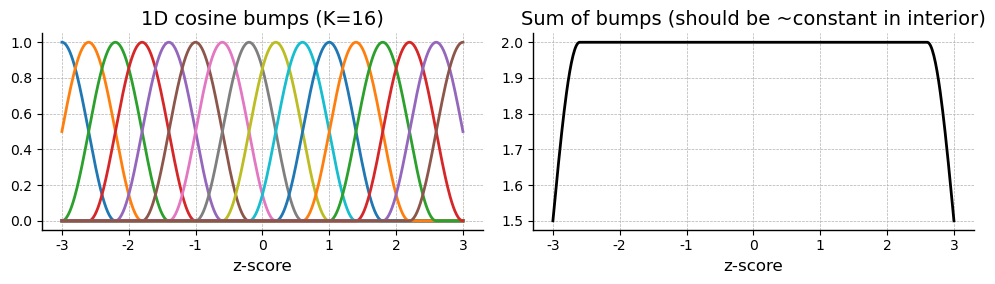

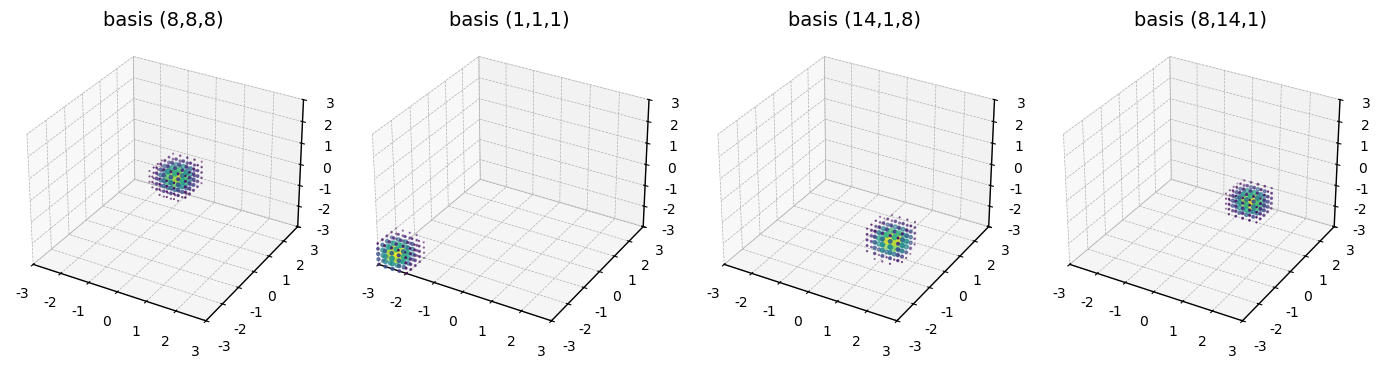

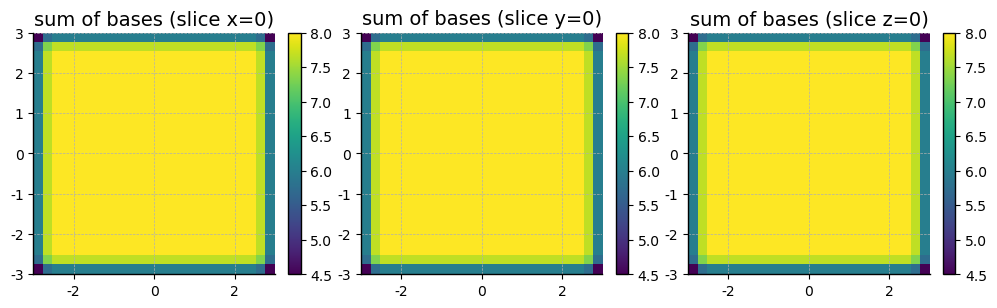

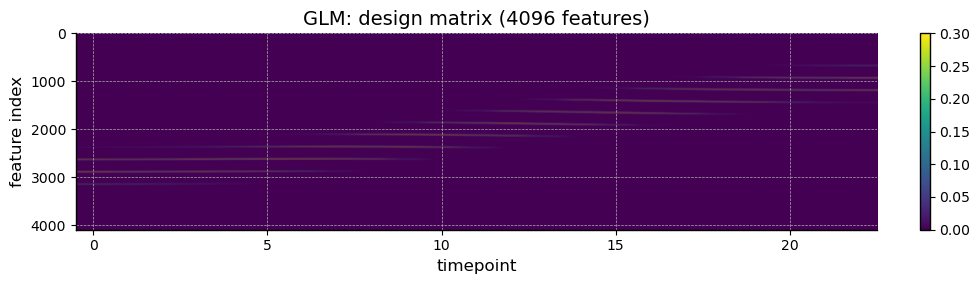

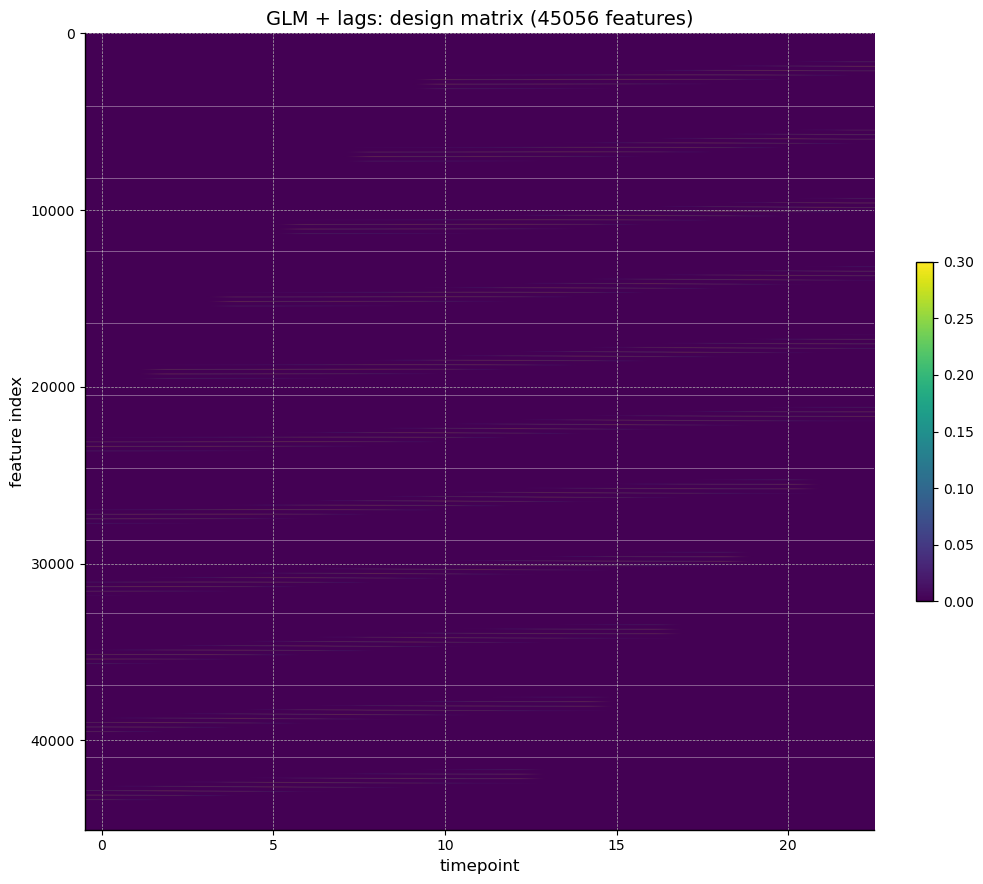

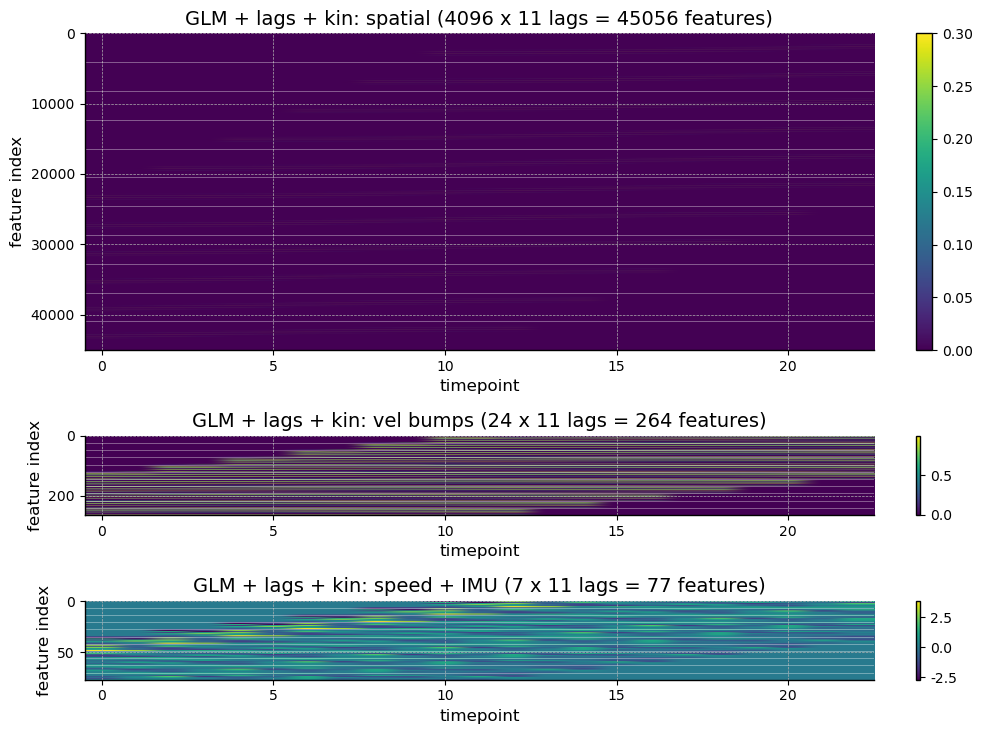

In [38]:
centers = models[('GLM', 'position')].centers.cpu().numpy()
width = models[('GLM', 'position')].width
K = models[('GLM', 'position')].n_bases_per_dim
lo, hi = float(centers[0]), float(centers[-1])

# --- (1) 1D bumps along one axis ---
xs = torch.linspace(lo, hi, 500)
b1d = create_cosine_bumps_torch(xs, models[('GLM', 'position')].centers, width).cpu().numpy()
fig, axes = plt.subplots(1, 2, figsize=(10, 3))
axes[0].plot(xs.numpy(), b1d)
axes[0].set(title=f'1D cosine bumps (K={K})', xlabel='z-score')
axes[1].plot(xs.numpy(), b1d.sum(axis=1), 'k')
axes[1].set(title='Sum of bumps (should be ~constant in interior)', xlabel='z-score')
plt.tight_layout(); plt.show()

# --- (2) Selected 3D basis functions over a 3D grid ---
N_GRID = 25
g_pts = torch.linspace(lo, hi, N_GRID)
X3, Y3, Z3 = torch.meshgrid(g_pts, g_pts, g_pts, indexing='ij')
grid = torch.stack([X3.flatten(), Y3.flatten(), Z3.flatten()], dim=-1)
bx = create_cosine_bumps_torch(grid[:, 0], models[('GLM', 'position')].centers, width)
by = create_cosine_bumps_torch(grid[:, 1], models[('GLM', 'position')].centers, width)
bz = create_cosine_bumps_torch(grid[:, 2], models[('GLM', 'position')].centers, width)
bases_grid = (bx.unsqueeze(-1).unsqueeze(-1)
              * by.unsqueeze(-2).unsqueeze(-1)
              * bz.unsqueeze(-2).unsqueeze(-2)).flatten(-3).cpu().numpy()

chosen = [(K // 2, K // 2, K // 2), (1, 1, 1), (K - 2, 1, K // 2), (K // 2, K - 2, 1)]
fig = plt.figure(figsize=(14, 3.5))
for i, (ix, iy, iz) in enumerate(chosen):
    flat_idx = ix * K * K + iy * K + iz
    vals = bases_grid[:, flat_idx]
    keep = vals > 0.01
    ax = fig.add_subplot(1, 4, i + 1, projection='3d')
    ax.scatter(grid[keep, 0].cpu(), grid[keep, 1].cpu(), grid[keep, 2].cpu(),
               c=vals[keep], s=20 * vals[keep], cmap='viridis')
    ax.set(title=f'basis ({ix},{iy},{iz})',
           xlim=(lo, hi), ylim=(lo, hi), zlim=(lo, hi))
plt.tight_layout(); plt.show()

# --- (3) Sum-of-bases slices ---
total = bases_grid.sum(axis=1).reshape(N_GRID, N_GRID, N_GRID)
mid = N_GRID // 2
fig, axes = plt.subplots(1, 3, figsize=(10, 3))
for ax, sl, sname in zip(axes,
                         [total[mid], total[:, mid], total[:, :, mid]],
                         ['x=0', 'y=0', 'z=0']):
    im = ax.imshow(sl, extent=[lo, hi, lo, hi], origin='lower')
    ax.set_title(f'sum of bases (slice {sname})')
    plt.colorbar(im, ax=ax, fraction=0.046)
plt.tight_layout(); plt.show()

# --- (4) Design matrix on a real test batch for each GLM variant ---
session_name = list(dataloaders['test'].keys())[0]
batch = next(iter(dataloaders['test'][session_name]))
batch_kin = next(iter(dataloaders_kin['test'][session_name]))

for name in ['GLM', 'GLM + lags', 'GLM + lags + kin']:
    model = models[(name, 'position')]
    if 'kin' in name:
        xr, mr = batch_kin.behavior, batch_kin.mask
        with torch.no_grad():
            design = model._make_design(xr, mr, session_name=session_name)
    else:
        xr, mr = batch.behavior, batch.mask
        with torch.no_grad():
            design = model._make_design(xr, mr)

    valid = mr[0] == 1.0
    design_valid = design[0, valid].cpu().numpy()
    n_features = design_valid.shape[1]
    n_lags = len(model.lag_bins)

    if 'kin' in name:
        K3 = model.n_bases_per_dim ** 3
        n_vel = model.n_vel_bumps * 3
        n_extra = 7  # speed (1) + IMU (6)
        per_lag = K3 + n_vel + n_extra
        groups = [
            ('spatial', 0, K3, 0.3),
            ('vel bumps', K3, K3 + n_vel, None),
            ('speed + IMU', K3 + n_vel, per_lag, None),
        ]
        fig, axes = plt.subplots(len(groups), 1, figsize=(10, 2.5 * len(groups)),
                                  height_ratios=[4, 1, 1])
        for ax, (gname, g_start, g_end, vmax) in zip(axes, groups):
            blocks = [design_valid[:, lag * per_lag + g_start: lag * per_lag + g_end]
                      for lag in range(n_lags)]
            block = np.concatenate(blocks, axis=1)
            im = ax.imshow(block.T, aspect='auto', cmap='viridis', vmax=vmax)
            g_size = g_end - g_start
            ax.set(xlabel='timepoint', ylabel='feature index',
                   title=f'{name}: {gname} ({g_size} x {n_lags} lags = {block.shape[1]} features)')
            if n_lags > 1:
                for k in range(1, n_lags):
                    ax.axhline(k * g_size - 0.5, color='white', lw=0.5, alpha=0.5)
            plt.colorbar(im, ax=ax, fraction=0.02)
        plt.tight_layout(); plt.show()
    else:
        fig, ax = plt.subplots(figsize=(10, 3 * max(n_lags // 3, 1)))
        im = ax.imshow(design_valid.T, aspect='auto', cmap='viridis', vmax=0.3)
        ax.set(xlabel='timepoint', ylabel='feature index',
               title=f'{name}: design matrix ({n_features} features)')
        if n_lags > 1:
            K3 = n_features // n_lags
            for k in range(1, n_lags):
                ax.axhline(k * K3 - 0.5, color='white', lw=0.5, alpha=0.5)
        plt.colorbar(im, ax=ax, fraction=0.02)
        plt.tight_layout(); plt.show()

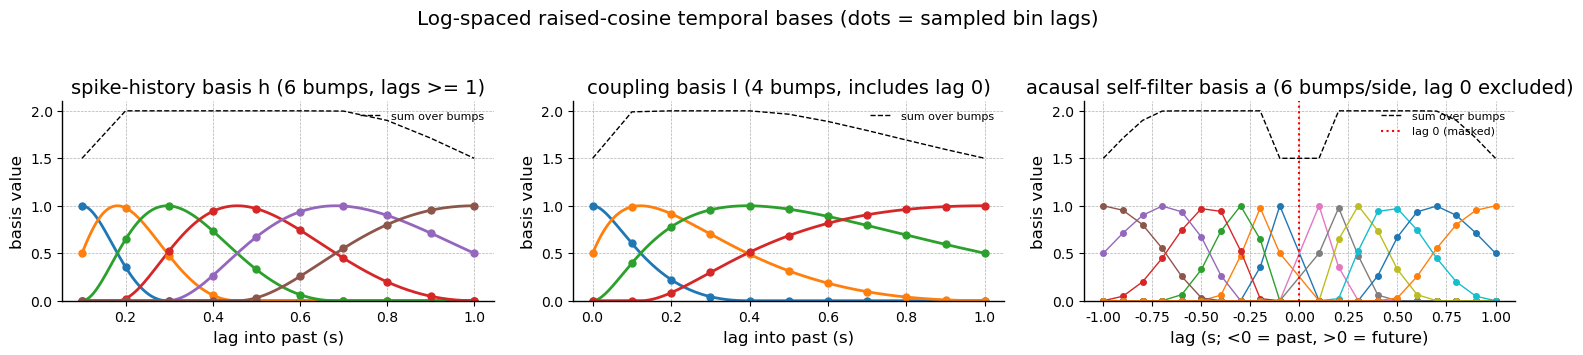

history basis  (10, 6) (lags [0.1 0.2 0.3 0.4 0.5 0.6 0.7 0.8 0.9 1. ])
coupling basis (11, 4) (lags [0.  0.1 0.2 0.3 0.4 0.5 0.6 0.7 0.8 0.9 1. ])
acausal basis  (20, 12) (lags [-1.  -0.9 -0.8 -0.7 -0.6 -0.5 -0.4 -0.3 -0.2 -0.1  0.1  0.2  0.3  0.4
  0.5  0.6  0.7  0.8  0.9  1. ])


In [39]:
# Sanity-check the Pillow-style temporal-filter bases. Log-spaced raised cosines:
# fine resolution near the spike, coarse at long lags. The history basis (h) is
# strictly causal (lags >= 1 bin); the coupling basis (l) also includes lag 0
# (the simultaneous bin) since other neurons' current spikes are legitimate
# predictors (the self-diagonal is masked out). The acausal self-filter basis (a)
# is symmetric about lag 0 and spans both past and future lags, with lag 0
# EXCLUDED (masked) so a neuron's current bin never predicts itself.
def _dense_basis(n_basis, lags, c):
    t = np.linspace(lags[0], lags[-1], 400)
    nlin = lambda x: np.log(x + c)
    ctr = np.linspace(nlin(lags[0]), nlin(lags[-1]), n_basis)
    db = ctr[1] - ctr[0] if n_basis > 1 else 1.0
    arg = (nlin(t)[:, None] - ctr[None, :]) * np.pi / (2 * db)
    return t, (np.cos(np.clip(arg, -np.pi, np.pi)) + 1.0) / 2.0


fig, axes = plt.subplots(1, 3, figsize=(15.5, 3.4))
panels = [
    (hist_basis, hist_lags, HIST_N_BASIS, f'spike-history basis h ({HIST_N_BASIS} bumps, lags >= 1)'),
    (coup_basis, coup_lags, COUP_N_BASIS, f'coupling basis l ({COUP_N_BASIS} bumps, includes lag 0)'),
]
for ax, (B, lags, nb, ttl) in zip(axes[:2], panels):
    td, Bd = _dense_basis(nb, lags, BIN_WIDTH)
    lines = ax.plot(td, Bd)
    for j, ln in enumerate(lines):
        ax.plot(lags, B[:, j], 'o', ms=5, color=ln.get_color())
    ax.plot(lags, B.numpy().sum(1), 'k--', lw=1, label='sum over bumps')
    ax.set(title=ttl, xlabel='lag into past (s)', ylabel='basis value', ylim=(0, 2.1))
    ax.legend(fontsize=8, loc='upper right')

# Acausal self-filter basis: symmetric past+future bumps, lag 0 masked out. Each
# column is nonzero on only one side (independent past vs. future weights); the
# dashed sum traces the one-sided envelope on each side.
ax = axes[2]
for j in range(acausal_basis.shape[1]):
    ax.plot(acausal_lags, acausal_basis[:, j], '-o', ms=4, lw=1)
ax.plot(acausal_lags, acausal_basis.numpy().sum(1), 'k--', lw=1, label='sum over bumps')
ax.axvline(0, color='r', ls=':', lw=1.5, label='lag 0 (masked)')
ax.set(title=f'acausal self-filter basis a ({ACAUSAL_N_BASIS} bumps/side, lag 0 excluded)',
       xlabel='lag (s; <0 = past, >0 = future)', ylabel='basis value', ylim=(0, 2.1))
ax.legend(fontsize=8, loc='upper right')
fig.suptitle('Log-spaced raised-cosine temporal bases (dots = sampled bin lags)', y=1.04)
plt.tight_layout(); plt.show()

print(f'history basis  {tuple(hist_basis.shape)} (lags {np.round(hist_lags, 2)})')
print(f'coupling basis {tuple(coup_basis.shape)} (lags {np.round(coup_lags, 2)})')
print(f'acausal basis  {tuple(acausal_basis.shape)} (lags {np.round(acausal_lags, 2)})')

In [40]:
# ---- GLM trainer (Poisson NLL) shared by all position-basis GLMs.
# Handles spike-history / coupling (needs the spike train) and joint conditioning
# (needs per-flight cluster ids). Coupling params get a smaller LR + group-lasso
# (strength alpha) instead of weight-decay, with global grad-norm clipping (the
# dense coupling block under the exp link is otherwise prone to blow-up).
def _val_fde_glm(model, dls, device, flight_cluster=None):
    model.eval(); scores = []
    is_joint = getattr(model, 'joint', False)
    with torch.no_grad():
        for s, sd in dls['valid'].items():
            yt, yp = [], []
            for b in sd:
                ci = (cluster_idx_from_fpi(b.flight_path_index.numpy(), s, flight_cluster).to(device)
                      if is_joint else None)
                m = b.mask.to(device)
                out = model(s, b.behavior.to(device), m,
                            spike=b.spike.to(device), cluster_idx=ci)
                v = m == 1.0
                yt.append(b.spike.to(device)[v].cpu().numpy())
                yp.append(out[v].cpu().numpy())
            scores.append(poisson_fde_population(np.vstack(yt), np.vstack(yp)))
    return float(np.nanmedian(np.hstack(scores)))


def train_glm(model, dls, device, alpha=0.0, weight_decay=1.0, flight_cluster=None,
              n_epochs=1000, lr=DEFAULT_LR, coup_lr=1e-3, grad_clip=5.0, patience=20):
    model = model.to(device)
    loss_fn = nn.PoissonNLLLoss(log_input=False).to(device)
    is_joint = getattr(model, 'joint', False)
    use_coup = getattr(model, 'use_coup', False)
    coup_ids = set(id(p) for p in model.coup_weights.parameters()) if use_coup else set()
    other = [p for p in model.parameters() if id(p) not in coup_ids]
    coup = [p for p in model.parameters() if id(p) in coup_ids]
    opt = torch.optim.AdamW(
        [{'params': other, 'weight_decay': weight_decay, 'lr': lr},
         {'params': coup, 'weight_decay': 0.0, 'lr': coup_lr}], lr=lr)
    best, best_w, no_imp, curve = -np.inf, None, 0, []
    for ep in range(n_epochs):
        model.train()
        for s, sd in dls['train'].items():
            for b in sd:
                ci = (cluster_idx_from_fpi(b.flight_path_index.numpy(), s, flight_cluster).to(device)
                      if is_joint else None)
                X = b.behavior.to(device); Y = b.spike.to(device); M = b.mask.to(device)
                out = model(s, X, M, spike=Y, cluster_idx=ci)
                v = M == 1.0
                loss = loss_fn(out[v], Y[v])
                if use_coup:
                    loss = loss + alpha * coupling_group_penalty(model.coup_weights[s])
                opt.zero_grad(); loss.backward()
                if grad_clip is not None:
                    torch.nn.utils.clip_grad_norm_(model.parameters(), grad_clip)
                opt.step()
        val = _val_fde_glm(model, dls, device, flight_cluster); curve.append(val)
        if val > best:
            best, best_w, no_imp = val, deepcopy(model.state_dict()), 0
        else:
            no_imp += 1
            if no_imp >= patience:
                break
    if best_w is not None:
        model.load_state_dict(best_w)
    return best, best_w, curve


def tune_glm(make_model, dls, device, search_alpha, flight_cluster=None,
             n_trials=GLM_N_TRIALS, tag='', **train_kw):
    """Optuna search over weight_decay (+ coupling alpha when search_alpha).
    Shows a trial-level progress bar and logs each trial + running best.
    Returns (best_model, best_params, best_val)."""
    optuna.logging.set_verbosity(optuna.logging.WARNING)

    def objective(trial):
        wd = trial.suggest_float('weight_decay', *GLM_WD_RANGE, log=True)
        alpha = (trial.suggest_float('alpha', *GLM_ALPHA_RANGE, log=True)
                 if search_alpha else 0.0)
        set_random_state(seed)
        m = make_model().to(device)
        val, _, _ = train_glm(m, dls, device, alpha=alpha, weight_decay=wd,
                              flight_cluster=flight_cluster, **train_kw)
        return val

    def _log_trial(study, trial):
        tv = trial.value if trial.value is not None else float('nan')
        print(f'    [{tag}] trial {trial.number + 1}/{n_trials}: '
              f'params={trial.params} val FDE={tv:+.4f} | '
              f'best={study.best_value:+.4f} {study.best_params}', flush=True)

    study = optuna.create_study(direction='maximize',
                                sampler=optuna.samplers.TPESampler(seed=seed))
    study.optimize(objective, n_trials=n_trials, show_progress_bar=True,
                   callbacks=[_log_trial])
    bp = study.best_params
    print(f'    [{tag}] retraining at best params {bp} ...', flush=True)
    set_random_state(seed)
    m = make_model().to(device)
    val, _, _ = train_glm(m, dls, device, alpha=bp.get('alpha', 0.0),
                          weight_decay=bp['weight_decay'],
                          flight_cluster=flight_cluster, **train_kw)
    return m, bp, val


## Train missing checkpoints

For each `(model, conditioning)` with a missing/incompatible checkpoint:

- **Transformer / MLP only** — `bat_former_trainer` at the default LR/WD.
- **Pre-existing GLM / +lags / +lags+kin (position)** — the legacy weight-decay
  grid (kept so their existing checkpoints are reused without retraining).
- **New GLMs (+hist / +coup / +hist+coup) and ALL joint GLMs** — **Optuna**
  selects `weight_decay` (and, for the coupled variants, the coupling group-lasso
  strength `alpha`, jointly). `alpha` ranges over `[1e-3, 1e1]` (includes 10.0).

Compatible checkpoints are skipped. Optuna runs `GLM_N_TRIALS` trials per model
(raise toward 20 for a finer search); each trial trains to early stopping.


In [41]:
# Train any (model, conditioning) whose checkpoint is missing/incompatible.
#  - Transformer / MLP only: bat_former_trainer at the default LR/WD.
#  - EVERY GLM (plain / +lags / +lags+kin / +hist / +coup / +hist+coup / +acausal,
#    position or joint): Optuna over weight_decay (log-uniform GLM_WD_RANGE), plus
#    coupling alpha for the coupled variants.  The searched params are persisted
#    per-split (see GLM_PARAMS_PATH) and reused on later runs so the expensive
#    search runs at most once per split.
import json

GLM_BEST_PARAMS = {}

# Persisted Optuna GLM hyperparameters for THIS split (keyed by DATA_TAG).  The
# search is expensive and the old (pre-split-change) params were never saved, so
# the first run on a new split re-searches and records them here; later runs (or
# any future split reusing the same DATA_TAG) reuse them and skip Optuna.
GLM_PARAMS_PATH = f'./out/bat_glm/glm_best_params{DATA_TAG}_seed_{seed}.json'
if os.path.exists(GLM_PARAMS_PATH):
    with open(GLM_PARAMS_PATH) as f:
        glm_saved_params = json.load(f)
    print(f'Loaded {len(glm_saved_params)} saved GLM hyperparameter set(s) from {GLM_PARAMS_PATH}')
else:
    glm_saved_params = {}

for key in FIT_SPECS:
    name, cond = key
    if ckpt_compat[key]:
        print(f'[{name} | {cond}] checkpoint exists & compatible — skipping.')
        continue
    dls, mi = data_for(name, cond)
    path = CKPT_PATHS[key]
    os.makedirs(os.path.dirname(path), exist_ok=True)

    if name in ('Transformer', 'MLP only'):
        print(f'[{name}] training ...')
        set_random_state(seed)
        models[key] = build_model(name, cond).to(device)
        tc = make_trainer_config(model=models[key], dataloaders=dls, device=device,
                                 model_name=path, lr=DEFAULT_LR,
                                 weight_decay=DEFAULT_WEIGHT_DECAY)
        bv, _, _ = bat_former_trainer(**tc)
        print(f'  best val FDE = {bv:.4f}')
        continue

    # Every GLM: Optuna over weight_decay (+ coupling alpha for coupled variants).
    search_alpha = 'coup' in name
    fc = flight_cluster if cond == 'joint' else None
    pkey = f'{name}|{cond}'
    if pkey in glm_saved_params:
        bp = glm_saved_params[pkey]
        print(f'[{name} | {cond}] reusing saved hyperparameters {bp} (skipping Optuna) ...')
        set_random_state(seed)
        m = build_model(name, cond).to(device)
        bv, _, _ = train_glm(m, dls, device, alpha=bp.get('alpha', 0.0),
                             weight_decay=bp['weight_decay'], flight_cluster=fc)
    else:
        print(f'[{name} | {cond}] Optuna ({GLM_N_TRIALS} trials, search_alpha={search_alpha}) ...')
        m, bp, bv = tune_glm(lambda: build_model(name, cond), dls, device,
                             search_alpha=search_alpha, flight_cluster=fc,
                             tag=f'{name} | {cond}')
        glm_saved_params[pkey] = bp
        with open(GLM_PARAMS_PATH, 'w') as f:
            json.dump(glm_saved_params, f, indent=2)
    models[key] = m; torch.save(m.state_dict(), path)
    GLM_BEST_PARAMS[key] = bp
    print(f'  best params={bp} (val FDE={bv:+.4f}); saved {path}')

ckpt_compat = {key: True for key in FIT_SPECS}
if GLM_BEST_PARAMS:
    print('\nSelected GLM hyperparameters:')
    for key, bp in GLM_BEST_PARAMS.items():
        print(f'  {key[0]:<18} [{key[1]:<8}]: {bp}')

Loaded 3 saved GLM hyperparameter set(s) from ./out/bat_glm/glm_best_params_acc50_seed_1.json
[GLM | position] Optuna (10 trials, search_alpha=False) ...


  0%|          | 0/10 [00:00<?, ?it/s]

    [GLM | position] trial 1/10: params={'weight_decay': 0.023801037902772264} val FDE=-0.0342 | best=-0.0342 {'weight_decay': 0.023801037902772264}
    [GLM | position] trial 2/10: params={'weight_decay': 1.2738188799721928} val FDE=-0.0680 | best=-0.0342 {'weight_decay': 0.023801037902772264}
    [GLM | position] trial 3/10: params={'weight_decay': 0.00010015019947803607} val FDE=-0.0325 | best=-0.0325 {'weight_decay': 0.00010015019947803607}
    [GLM | position] trial 4/10: params={'weight_decay': 0.005284261032065129} val FDE=-0.0329 | best=-0.0325 {'weight_decay': 0.00010015019947803607}
    [GLM | position] trial 5/10: params={'weight_decay': 0.0006860526081596928} val FDE=-0.0325 | best=-0.0325 {'weight_decay': 0.0006860526081596928}
    [GLM | position] trial 6/10: params={'weight_decay': 0.00033591924214088173} val FDE=-0.0325 | best=-0.0325 {'weight_decay': 0.0006860526081596928}
    [GLM | position] trial 7/10: params={'weight_decay': 0.0011521031330181126} val FDE=-0.0325 |

  0%|          | 0/10 [00:00<?, ?it/s]

GLM: 11 lags x 4096 spatial = 45056 features, lag_bins=[-10, -8, -6, -4, -2, 0, 2, 4, 6, 8, 10]
    [GLM + lags | position] trial 1/10: params={'weight_decay': 0.023801037902772264} val FDE=-0.0362 | best=-0.0362 {'weight_decay': 0.023801037902772264}
GLM: 11 lags x 4096 spatial = 45056 features, lag_bins=[-10, -8, -6, -4, -2, 0, 2, 4, 6, 8, 10]
    [GLM + lags | position] trial 2/10: params={'weight_decay': 1.2738188799721928} val FDE=+0.0271 | best=+0.0271 {'weight_decay': 1.2738188799721928}
GLM: 11 lags x 4096 spatial = 45056 features, lag_bins=[-10, -8, -6, -4, -2, 0, 2, 4, 6, 8, 10]
    [GLM + lags | position] trial 3/10: params={'weight_decay': 0.00010015019947803607} val FDE=-0.0378 | best=+0.0271 {'weight_decay': 1.2738188799721928}
GLM: 11 lags x 4096 spatial = 45056 features, lag_bins=[-10, -8, -6, -4, -2, 0, 2, 4, 6, 8, 10]
    [GLM + lags | position] trial 4/10: params={'weight_decay': 0.005284261032065129} val FDE=-0.0377 | best=+0.0271 {'weight_decay': 1.2738188799721928

...

    [GLM + coup | joint] trial 1/10: params={'weight_decay': 0.023801037902772264, 'alpha': 2.098683560764662} val FDE=+0.0469 | best=+0.0469 {'weight_decay': 0.023801037902772264, 'alpha': 2.098683560764662}
    [GLM + coup | joint] trial 2/10: params={'weight_decay': 0.00010015019947803607, 'alpha': 0.006516215458215695} val FDE=+0.0366 | best=+0.0469 {'weight_decay': 0.023801037902772264, 'alpha': 2.098683560764662}
    [GLM + coup | joint] trial 3/10: params={'weight_decay': 0.0006860526081596928, 'alpha': 0.0003581224678700232} val FDE=+0.0366 | best=+0.0469 {'weight_decay': 0.023801037902772264, 'alpha': 2.098683560764662}
    [GLM + coup | joint] trial 4/10: params={'weight_decay': 0.0011521031330181126, 'alpha': 0.011840345146135165} val FDE=+0.0366 | best=+0.0469 {'weight_decay': 0.023801037902772264, 'alpha': 2.098683560764662}
    [GLM + coup | joint] trial 5/10: params={'weight_decay': 0.018245927057608576, 'alpha': 0.17096232052870358} val FDE=+0.0385 | best=+0.0469 {'weig

  0%|          | 0/10 [00:00<?, ?it/s]

    [GLM + hist + coup | joint] trial 1/10: params={'weight_decay': 0.023801037902772264, 'alpha': 2.098683560764662} val FDE=+0.0734 | best=+0.0734 {'weight_decay': 0.023801037902772264, 'alpha': 2.098683560764662}
    [GLM + hist + coup | joint] trial 2/10: params={'weight_decay': 0.00010015019947803607, 'alpha': 0.006516215458215695} val FDE=+0.0660 | best=+0.0734 {'weight_decay': 0.023801037902772264, 'alpha': 2.098683560764662}
    [GLM + hist + coup | joint] trial 3/10: params={'weight_decay': 0.0006860526081596928, 'alpha': 0.0003581224678700232} val FDE=+0.0659 | best=+0.0734 {'weight_decay': 0.023801037902772264, 'alpha': 2.098683560764662}
    [GLM + hist + coup | joint] trial 4/10: params={'weight_decay': 0.0011521031330181126, 'alpha': 0.011840345146135165} val FDE=+0.0662 | best=+0.0734 {'weight_decay': 0.023801037902772264, 'alpha': 2.098683560764662}
    [GLM + hist + coup | joint] trial 5/10: params={'weight_decay': 0.018245927057608576, 'alpha': 0.17096232052870358} va

  0%|          | 0/10 [00:00<?, ?it/s]

    [GLM + acausal | joint] trial 1/10: params={'weight_decay': 0.023801037902772264} val FDE=+0.0208 | best=+0.0208 {'weight_decay': 0.023801037902772264}
    [GLM + acausal | joint] trial 2/10: params={'weight_decay': 1.2738188799721928} val FDE=-0.0358 | best=+0.0208 {'weight_decay': 0.023801037902772264}
    [GLM + acausal | joint] trial 3/10: params={'weight_decay': 0.00010015019947803607} val FDE=+0.0201 | best=+0.0208 {'weight_decay': 0.023801037902772264}
    [GLM + acausal | joint] trial 4/10: params={'weight_decay': 0.005284261032065129} val FDE=+0.0204 | best=+0.0208 {'weight_decay': 0.023801037902772264}
    [GLM + acausal | joint] trial 5/10: params={'weight_decay': 0.0006860526081596928} val FDE=+0.0200 | best=+0.0208 {'weight_decay': 0.023801037902772264}
    [GLM + acausal | joint] trial 6/10: params={'weight_decay': 0.00033591924214088173} val FDE=+0.0200 | best=+0.0208 {'weight_decay': 0.023801037902772264}
    [GLM + acausal | joint] trial 7/10: params={'weight_decay

## Load all checkpoints

In [42]:
for key in FIT_SPECS:
    path = CKPT_PATHS[key]
    state = torch.load(path, map_location=device)
    models[key].load_state_dict(state, strict=True)
    models[key] = models[key].to(device).eval()
    print(f'[{key[0]} | {key[1]}] loaded {path}')


[GLM | position] loaded ./out/bat_glm/bat_glm_position_seed_1_optuna_acc50.pth
[GLM + lags | position] loaded ./out/bat_glm/bat_glm_lags_position_seed_1_optuna_acc50.pth
[GLM + lags + kin | position] loaded ./out/bat_glm/bat_glm_lags_kin_position_seed_1_optuna_acc50.pth
[GLM + hist | position] loaded ./out/bat_glm/bat_glm_hist_position_seed_1_optuna_acc50.pth
[GLM + coup | position] loaded ./out/bat_glm/bat_glm_coup_position_seed_1_optuna_acc50.pth
[GLM + hist + coup | position] loaded ./out/bat_glm/bat_glm_hist_coup_position_seed_1_optuna_acc50.pth
[GLM + acausal | position] loaded ./out/bat_glm/bat_glm_acausal_position_seed_1_optuna_acc50.pth
[MLP only | position] loaded ./out/bat_former_no_attn/bat_former_seed_1_lr_1.00e-02_wd_1.00e-02_acc50.pth
[Transformer | position] loaded ./out/bat_former/bat_former_seed_1_lr_1.00e-02_wd_1.00e-02_acc50.pth
[GLM | joint] loaded ./out/bat_glm/bat_glm_joint_seed_1_optuna_acc50.pth
[GLM + hist | joint] loaded ./out/bat_glm/bat_glm_hist_joint_seed_1

## Evaluation

Copy of `evaluate_model` from `preprocess-data-v0j-share.ipynb` so this notebook
is self-contained. Each model is evaluated against its routed dataloader
(`DATA_BY_MODEL[name]`): base for everything except `GLM + lags + kin`, which
uses the kinematics dataloader.

In [43]:
def evaluate_model(model, dataloaders, valid_fn, device, flight_filter=None,
                   meta_info_dict=None, flight_cluster=None):
    """Test-set evaluation; returns {session_name: per-neuron scores}.

    `GLM_Coupled` models additionally receive the spike train (for the
    history/coupling filters) and, when joint, per-flight cluster ids. Using the
    true past spikes is the standard GLM encoding evaluation (conditional
    intensity given observed history)."""
    results = {}
    model.eval()
    is_coupled = isinstance(model, GLM_Coupled)
    is_joint = getattr(model, 'joint', False)
    for session_name, session_data in dataloaders['test'].items():
        if flight_filter == 'ood':
            target_types = np.array(meta_info_dict['flight_type_test_ood'][session_name], dtype=int)
            if target_types.size == 0:
                results[session_name] = np.array([]); continue
        elif flight_filter == 'indomain':
            target_types = np.array(meta_info_dict['flight_type_test_indomain'][session_name], dtype=int)
        else:
            target_types = None

        y_val_list, y_pred_list = [], []
        for batch in session_data:
            X_val = batch.behavior.to(device)
            y_val = batch.spike.to(device)
            mask_val = batch.mask.to(device)
            fpi = batch.flight_path_index.numpy()
            if target_types is not None:
                bm = np.isin(batch.flight_type_index.numpy(), target_types)
                if not bm.any():
                    continue
                X_val, y_val, mask_val, fpi = X_val[bm], y_val[bm], mask_val[bm], fpi[bm]
            if is_coupled:
                ci = (cluster_idx_from_fpi(fpi, session_name, flight_cluster).to(device)
                      if is_joint else None)
                y_pred = model(session_name, X_val, mask_val, spike=y_val, cluster_idx=ci)
            else:
                y_pred = model(session_name, X_val, mask_val)
            y_val_list.append(y_val[mask_val == 1.0].detach().cpu().numpy())
            y_pred_list.append(y_pred[mask_val == 1.0].detach().cpu().numpy())
        results[session_name] = (valid_fn(np.vstack(y_val_list), np.vstack(y_pred_list))
                                 if y_val_list else np.array([]))
    return results


In [44]:
metrics = {
    'corr': lambda yt, yp: corr(yt, yp, axis=0),
    'fde':  lambda yt, yp: poisson_fde_population(yt, yp),
}
flight_filters = [None, 'ood', 'indomain']

results_by_model = {key: {} for key in FIT_SPECS}
for key in FIT_SPECS:
    name, cond = key
    dls, mi = data_for(name, cond)
    fc = flight_cluster if cond == 'joint' else None
    for metric_name, valid_fn in metrics.items():
        for ff in flight_filters:
            mkey = f'{metric_name}_{ff or "all"}'
            results_by_model[key][mkey] = evaluate_model(
                models[key], dls, valid_fn, device,
                flight_filter=ff, meta_info_dict=mi, flight_cluster=fc)
            scores = np.hstack([v for v in results_by_model[key][mkey].values() if len(v) > 0])
            stat = np.nanmedian if 'fde' in mkey else np.nanmean
            print(f'  [{name:<18} {cond:<8}] {mkey:<14}: {stat(scores):+.4f}')


  [GLM                position] corr_all      : +0.1980
  [GLM                position] corr_ood      : +0.0655
  [GLM                position] corr_indomain : +0.2317
  [GLM                position] fde_all       : -0.0074
  [GLM                position] fde_ood       : -0.3624
  [GLM                position] fde_indomain  : +0.0237
  [GLM + lags         position] corr_all      : +0.2574
  [GLM + lags         position] corr_ood      : +0.0903
  [GLM + lags         position] corr_indomain : +0.2854
  [GLM + lags         position] fde_all       : +0.0382
  [GLM + lags         position] fde_ood       : -0.4064
  [GLM + lags         position] fde_indomain  : +0.0924
  [GLM + lags + kin   position] corr_all      : +0.2508
  [GLM + lags + kin   position] corr_ood      : +0.0919
  [GLM + lags + kin   position] corr_indomain : +0.2766
  [GLM + lags + kin   position] fde_all       : +0.0249
  [GLM + lags + kin   position] fde_ood       : -0.5063
  [GLM + lags + kin   position] fde_indomain  : 

## Long-form DataFrame

One row per (model, session, neuron, metric, flight_filter). The neuron index
within a session is consistent across models (all five share `unit_num_dict` for
non-kin variants; kin uses `unit_num_dict_kin`, which has the same session keys
and the same neuron counts as the base loader).

In [45]:
rows = []
for (name, cond), by_key in results_by_model.items():
    for mkey, by_session in by_key.items():
        metric, flight_filter = mkey.split('_', 1)
        for session, scores in by_session.items():
            if scores.size == 0:
                continue
            bat = parse_bat(session)
            for unit, score in enumerate(scores):
                rows.append({'model': name, 'conditioning': cond, 'session': session,
                             'bat': bat, 'unit': unit, 'metric': metric,
                             'flight_filter': flight_filter, 'score': score})
df = pd.DataFrame(rows)
df['model'] = pd.Categorical(df['model'], categories=MODEL_ORDER, ordered=True)
df['conditioning'] = pd.Categorical(df['conditioning'], categories=CONDITIONINGS, ordered=True)
df['flight_filter'] = pd.Categorical(df['flight_filter'],
                                     categories=['all', 'indomain', 'ood'], ordered=True)

# The main comparison (next few cells) uses position conditioning (all 8 models).
# The joint-vs-position comparison for the GLM family is a dedicated section below.
df_pos = df[df['conditioning'] == 'position'].copy()
df_pos['model'] = pd.Categorical(df_pos['model'], categories=MODEL_ORDER, ordered=True)
print(df.shape, '| position rows:', df_pos.shape[0])
df.head()


(253512, 8) | position rows: 162972


,model,conditioning,session,bat,unit,metric,flight_filter,score
0,GLM,position,Dataset_3_14543_240420,14543,0,corr,all,0.395433
1,GLM,position,Dataset_3_14543_240420,14543,1,corr,all,0.387193
2,GLM,position,Dataset_3_14543_240420,14543,2,corr,all,0.139225
3,GLM,position,Dataset_3_14543_240420,14543,3,corr,all,0.502168
4,GLM,position,Dataset_3_14543_240420,14543,4,corr,all,0.440508


In [46]:
# Wide form (one row per neuron) so we can compute per-neuron deltas + scatters.
# Position conditioning only (the main 8-model comparison).
wide = df_pos.pivot_table(
    index=['session', 'bat', 'unit', 'metric', 'flight_filter'],
    columns='model', values='score', observed=False,
).reset_index()
wide.head()


model,session,bat,unit,metric,flight_filter,GLM,GLM + lags,GLM + lags + kin,GLM + hist,GLM + coup,GLM + hist + coup,GLM + acausal,MLP only,Transformer
0,Dataset_1_32622_231007,32622,0,corr,all,0.073098,0.140073,0.161238,0.074020,0.135157,0.123655,0.114987,0.104377,0.186401
1,Dataset_1_32622_231007,32622,0,corr,indomain,0.144962,0.236459,0.222045,0.147901,0.239656,0.230281,0.189384,0.143716,0.257487
2,Dataset_1_32622_231007,32622,0,corr,ood,-0.108180,-0.127480,-0.018964,-0.130978,-0.101538,-0.126191,-0.089422,-0.058073,-0.139936
3,Dataset_1_32622_231007,32622,0,fde,all,-0.179320,-0.242702,-0.268502,-0.218744,-0.095268,-0.121948,-0.216864,0.008962,0.025548
4,Dataset_1_32622_231007,32622,0,fde,indomain,-0.005233,-0.064192,-0.096503,-0.018731,0.051321,0.036974,-0.015988,0.020202,0.055580


## Per-session score, all encoders (position conditioning)

One paired point per session (median over neurons). Lines colored by bat
(memory rule: always use `bat_palette()`). FDE y-axis clipped to `[-1, 1]` in
the plot only — underlying values stay raw.

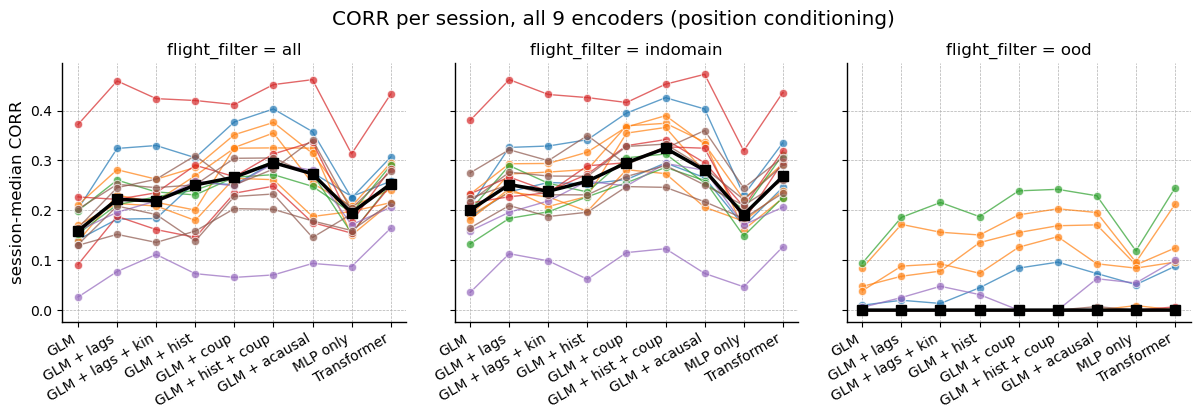

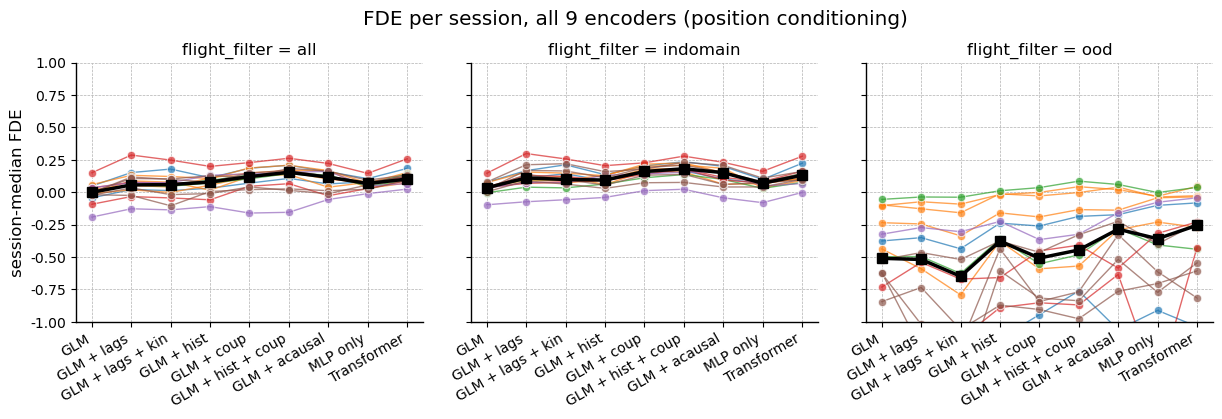

In [47]:
session_df = (
    df_pos.groupby(['metric', 'flight_filter', 'session', 'bat', 'model'], observed=True)
      .agg(score=('score', 'median'))
      .reset_index()
)

for metric in ['corr', 'fde']:
    g = sns.FacetGrid(
        session_df[session_df['metric'] == metric],
        col='flight_filter', col_order=['all', 'indomain', 'ood'],
        height=3.6, aspect=1.15, sharex=True, sharey=True,
    )
    g.map_dataframe(
        sns.lineplot, x='model', y='score', units='session',
        hue='bat', palette=BAT_PALETTE, hue_order=list(BAT_PALETTE.keys()),
        estimator=None, marker='o', alpha=0.7, linewidth=1, legend=False,
    )
    for flight_filter, ax in g.axes_dict.items():
        # Black line connecting per-model session-medians shows the trend.
        sub = (session_df[(session_df['metric'] == metric) &
                          (session_df['flight_filter'] == flight_filter)]
               .groupby('model', observed=True)['score'].median()
               .reindex(MODEL_ORDER))
        ax.plot(range(len(sub)), sub.values, color='k', linewidth=2.5, marker='s',
                markersize=7, label='cross-session median', zorder=5)
        ax.tick_params(axis='x', rotation=30)
        for lbl in ax.get_xticklabels():
            lbl.set_horizontalalignment('right')
        if metric == 'fde':
            ax.set_ylim(-1, 1)
    g.set_axis_labels('', f'session-median {metric.upper()}')
    g.figure.suptitle(f'{metric.upper()} per session, all {len(MODEL_ORDER)} encoders (position conditioning)', y=1.04)
    plt.show()


In [48]:
session_df[session_df['metric'] == 'fde'].groupby(['model', 'flight_filter'])['score'].median()

/tmp/ipykernel_3720572/1994052557.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  session_df[session_df['metric'] == 'fde'].groupby(['model', 'flight_filter'])['score'].median()


model              flight_filter
GLM                all             -0.000759
                   indomain         0.034511
                   ood             -0.509771
GLM + lags         all              0.056248
                   indomain         0.110220
                   ood             -0.518570
GLM + lags + kin   all              0.058693
                   indomain         0.098007
                   ood             -0.648371
GLM + hist         all              0.078482
                   indomain         0.093738
                   ood             -0.377303
GLM + coup         all              0.120263
                   indomain         0.159869
                   ood             -0.507661
GLM + hist + coup  all              0.153315
                   indomain         0.180404
                   ood             -0.445500
GLM + acausal      all              0.116179
                   indomain         0.150912
                   ood             -0.285265
MLP only           all

## Transformer vs. each baseline: significance

Wilcoxon signed-rank on the per-session-median scores between the full
`Transformer` and each of the four baselines (memory rule: session-level
nonparametric stats by default). Bracket + stars shown only when significant
(3 tiers, hide n.s.). Brackets stack vertically with the longest span at the
bottom.

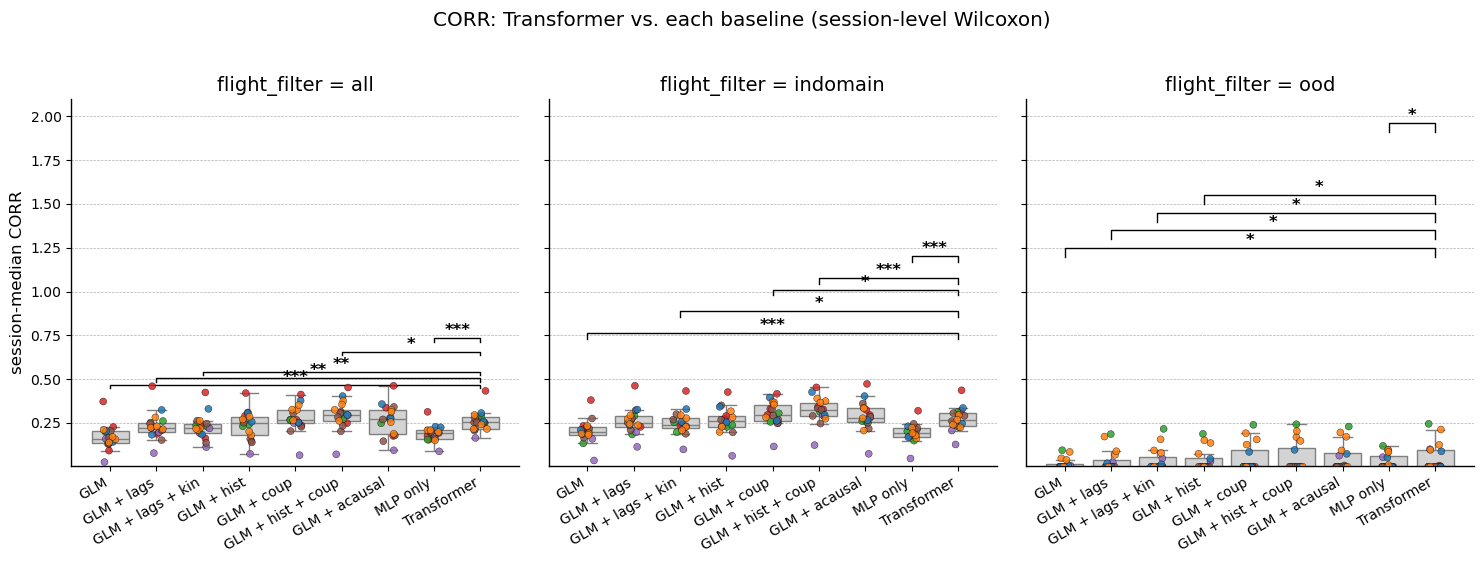

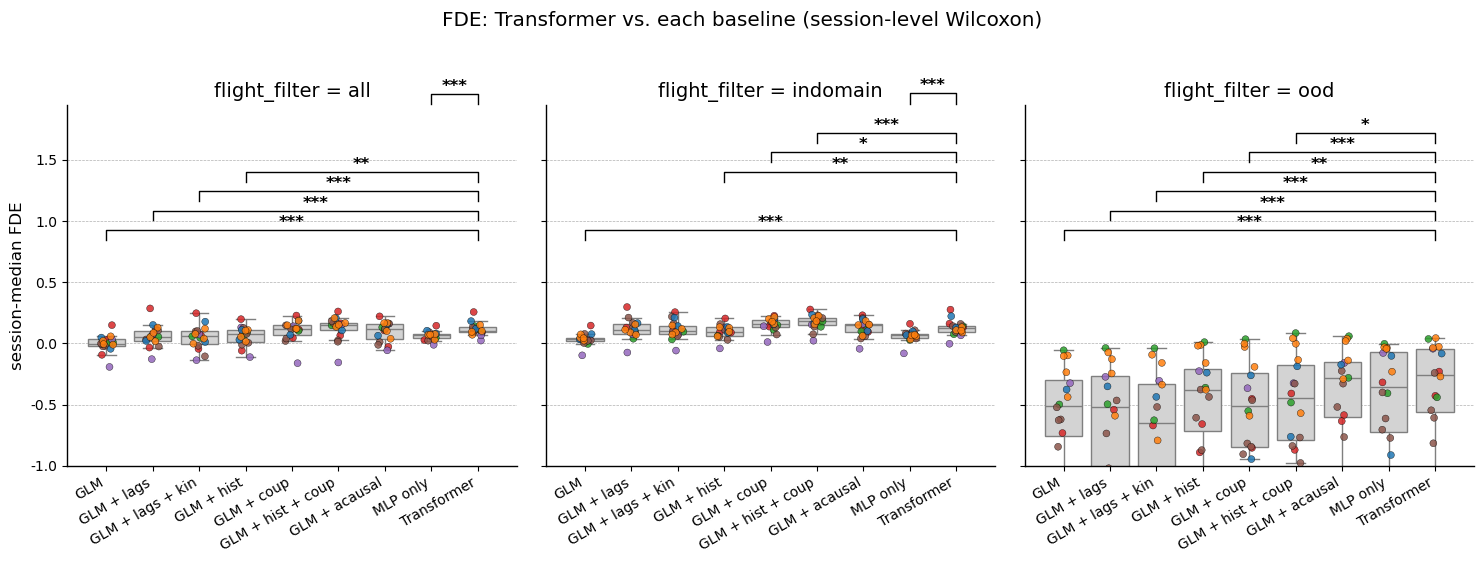

In [49]:
session_wide = session_df.pivot_table(
    index=['metric', 'flight_filter', 'session', 'bat'],
    columns='model', values='score', observed=False,
).reset_index()

# Transformer is the reference; compare against each baseline (longest-span
# bracket first so the closer ones stack above it).
TRANSFORMER_IDX = MODEL_ORDER.index('Transformer')
baseline_pairs = [(b, 'Transformer') for b in MODEL_ORDER if b != 'Transformer']

# Boxplot per metric x flight_filter, with Transformer-vs-baseline brackets.
for metric in ['corr', 'fde']:
    fig, axes = plt.subplots(1, 3, figsize=(15, 5.5), sharey=True)
    for ax, flight_filter in zip(axes, ['all', 'indomain', 'ood']):
        sub_long = session_df[(session_df['metric'] == metric) &
                              (session_df['flight_filter'] == flight_filter)]
        sns.boxplot(data=sub_long, x='model', y='score', order=MODEL_ORDER,
                    color='lightgray', showfliers=False, ax=ax)
        sns.stripplot(data=sub_long, x='model', y='score', order=MODEL_ORDER,
                      hue='bat', palette=BAT_PALETTE, hue_order=list(BAT_PALETTE.keys()),
                      dodge=False, jitter=0.15, size=5, alpha=0.85,
                      edgecolor='k', linewidth=0.3, ax=ax, legend=False)
        sub_wide = session_wide[(session_wide['metric'] == metric) &
                                (session_wide['flight_filter'] == flight_filter)]
        if metric == 'fde':
            ax.set_ylim(-1, 1)
        # Reserve headroom for stacked brackets above the data.
        ymin, ymax = ax.get_ylim()
        span = ymax - ymin
        ax.set_ylim(top=ymax + 0.32 * span)
        ymin, ymax = ax.get_ylim()
        span = ymax - ymin
        # Stack brackets bottom-up. baseline_pairs[0] has the longest span and
        # sits lowest; baseline_pairs[-1] (MLP only vs Transformer, the shortest
        # span) sits highest.
        base_y = ymax - 0.30 * span
        step = 0.06 * span
        for i, (m_a, m_b) in enumerate(baseline_pairs):
            paired = sub_wide[[m_a, m_b]].dropna()
            if len(paired) < 3:
                continue
            _, p = wilcoxon_safe((paired[m_b] - paired[m_a]).values)
            x1 = MODEL_ORDER.index(m_a)
            x2 = MODEL_ORDER.index(m_b)
            add_significance_bracket(ax, x1, x2, p, y=base_y + i * step)
        ax.tick_params(axis='x', rotation=30)
        for lbl in ax.get_xticklabels():
            lbl.set_horizontalalignment('right')
        ax.set_xlabel('')
        ax.set_ylabel(f'session-median {metric.upper()}')
        ax.set_title(f'flight_filter = {flight_filter}')
    fig.suptitle(f'{metric.upper()}: Transformer vs. each baseline (session-level Wilcoxon)', y=1.02)
    plt.tight_layout()
    plt.show()

## Per-neuron `Transformer − baseline` histograms

For each of the four non-Transformer models, plot the per-neuron difference
`Transformer − baseline` colored by bat. One row per baseline, one column per
metric. Vertical dashed line at zero is the no-effect reference; positive
density means Transformer wins for that neuron. FDE x-range clipped to
`[-1, 1]` in the plot only.

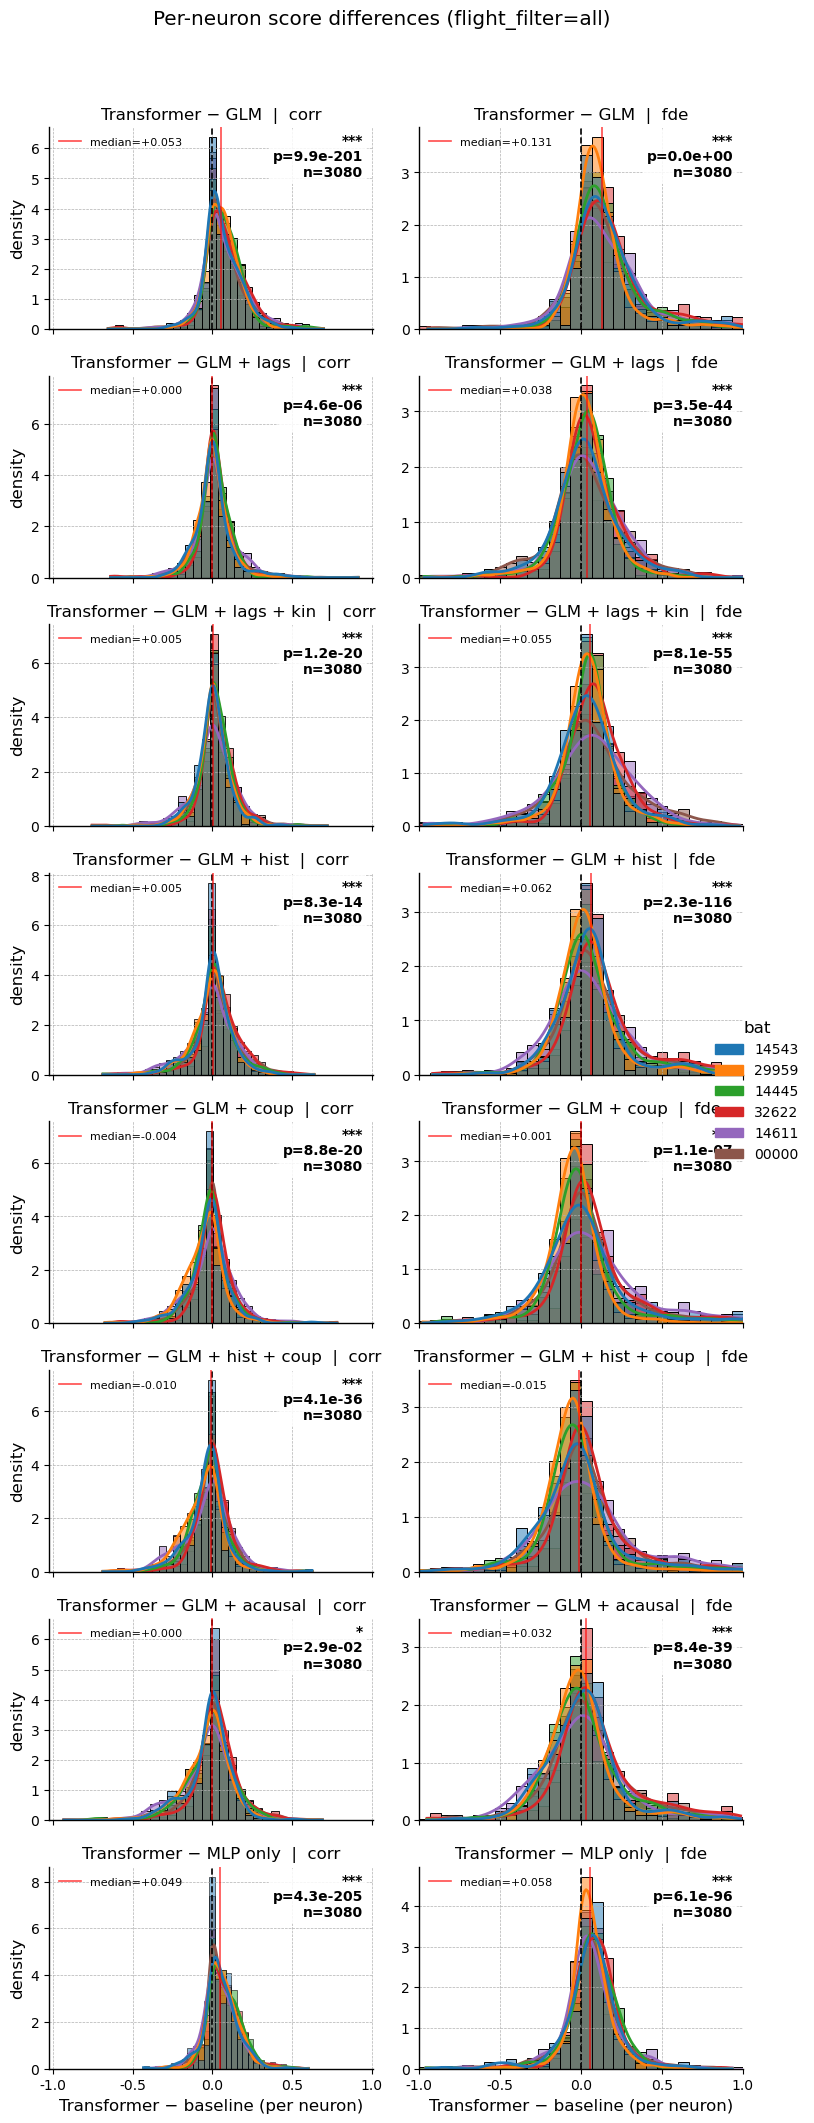

In [50]:
# Use only the 'all' flight filter for the histogram (mirrors the reference notebook).
diff_rows = []
baselines = [m for m in MODEL_ORDER if m != 'Transformer']

for metric in ['corr', 'fde']:
    sub = wide[(wide['metric'] == metric) & (wide['flight_filter'] == 'all')]
    for baseline in baselines:
        diff = (sub['Transformer'] - sub[baseline]).dropna()
        for d, bat in zip(diff, sub.loc[diff.index, 'bat']):
            diff_rows.append({
                'metric': metric, 'comparison': f'Transformer − {baseline}',
                'diff': d, 'bat': bat,
            })
df_diff = pd.DataFrame(diff_rows)

comparison_order = [f'Transformer − {b}' for b in baselines]
df_diff['comparison'] = pd.Categorical(df_diff['comparison'],
                                       categories=comparison_order, ordered=True)

def _hist_panel(data, color=None, **kwargs):
    """Per-facet histogram: FDE values are unbounded below, so we filter the
    visualized range to [-1, 1] and pin the binrange there. Underlying diffs
    stay raw — this only affects the plot (memory rule: clip in plots, not
    in computations)."""
    metric = data['metric'].iloc[0] if len(data) else None
    plot_data, binrange = data, None
    if metric == 'fde':
        plot_data = data[data['diff'].between(-1, 1)]
        binrange = (-1, 1)
    sns.histplot(data=plot_data, x='diff', hue='bat',
                 palette=BAT_PALETTE, hue_order=list(BAT_PALETTE.keys()),
                 bins=30, binrange=binrange, kde=True, alpha=0.5,
                 stat='density', common_norm=False, legend=False)

g = sns.FacetGrid(
    df_diff, col='metric', row='comparison',
    col_order=['corr', 'fde'], row_order=comparison_order,
    height=2.6, aspect=1.5, sharey=False, sharex='col',
)
g.map_dataframe(_hist_panel)
# Combine row+col into a single per-panel title so the right margin stays free.
g.set_titles(template='{row_name}  |  {col_name}')
for (comparison, metric), ax in g.axes_dict.items():
    sub = df_diff[(df_diff['comparison'] == comparison) &
                  (df_diff['metric'] == metric)]
    # Neuron-level Wilcoxon signed-rank: H0 median(diff) = 0.
    # FDE: run stats on the RAW (unclipped) diffs per the project memory rule.
    _, p = wilcoxon_safe(sub['diff'].values)
    median = float(np.median(sub['diff'])) if len(sub) else float('nan')
    ax.axvline(0, color='black', linestyle='--', lw=1.2)
    if np.isfinite(median):
        ax.axvline(median, color='red', linestyle='-', lw=1.2, alpha=0.7,
                   label=f'median={median:+.3f}')
        ax.legend(fontsize=8, loc='upper left', frameon=False)
    if metric == 'fde':
        ax.set_xlim(-1, 1)
    annotate_pvalue_corner(ax, p, n=len(sub))
g.set_axis_labels('Transformer − baseline (per neuron)', 'density')
# Manual bat-color legend (hue is inside each panel, not on FacetGrid).
import matplotlib.patches as mpatches
handles = [mpatches.Patch(color=BAT_PALETTE[b], label=b) for b in BAT_PALETTE]
g.figure.legend(handles=handles, title='bat', loc='center right',
                bbox_to_anchor=(1.05, 0.5), frameon=False)
g.figure.suptitle('Per-neuron score differences (flight_filter=all)', y=1.02)
plt.tight_layout()
plt.show()

## Summary tables

Per-model median across neurons (or sessions) and the full pairwise Wilcoxon
matrix on per-session medians.

In [51]:
neuron_summary = (
    df_pos.groupby(['metric', 'flight_filter', 'model'], observed=True)
      .agg(n_neurons=('score', 'size'),
           neuron_median=('score', 'median'),
           neuron_mean=('score', 'mean'))
      .reset_index()
)
neuron_summary


,metric,flight_filter,model,n_neurons,neuron_median,neuron_mean
0,corr,all,GLM,3080,0.150508,1.980115e-01
1,corr,all,GLM + lags,3080,0.213888,2.574147e-01
2,corr,all,GLM + lags + kin,3080,0.209381,2.507513e-01
3,corr,all,GLM + hist,3080,0.210707,2.544266e-01
4,corr,all,GLM + coup,3080,0.256880,2.861965e-01
5,corr,all,GLM + hist + coup,3080,0.274478,2.965028e-01
6,corr,all,GLM + acausal,3080,0.238627,2.791358e-01
7,corr,all,MLP only,3080,0.173986,2.057073e-01
8,corr,all,Transformer,3080,0.234324,2.668100e-01
9,corr,indomain,GLM,3080,0.185342,2.317231e-01


In [52]:
# Pairwise Wilcoxon signed-rank on per-session medians.
# Alternative: H1 = column model > row model. p < 0.05 means column beats row.
def stars(p):
    if not np.isfinite(p): return ''
    return '***' if p < 0.001 else '**' if p < 0.01 else '*' if p < 0.05 else 'n.s.'

pair_rows = []
for metric in ['corr', 'fde']:
    for flight_filter in ['all', 'indomain', 'ood']:
        sub = session_wide[(session_wide['metric'] == metric) &
                           (session_wide['flight_filter'] == flight_filter)]
        for m_a in MODEL_ORDER:
            for m_b in MODEL_ORDER:
                if m_a == m_b:
                    continue
                paired = sub[[m_a, m_b]].dropna()
                if len(paired) < 3:
                    continue
                diff = (paired[m_b] - paired[m_a]).values
                try:
                    _, p = wilcoxon(diff, alternative='greater')
                except ValueError:
                    p = np.nan
                pair_rows.append({
                    'metric': metric, 'flight_filter': flight_filter,
                    'row (baseline)': m_a, 'col (alternative)': m_b,
                    'n_sessions': len(paired),
                    'median_diff (col - row)': float(np.median(diff)),
                    'p (col > row)': p, 'sig': stars(p),
                })
pair_df = pd.DataFrame(pair_rows)

print('Transformer vs. each baseline:')
transformer_vs = pair_df[(pair_df['col (alternative)'] == 'Transformer') &
                         (pair_df['row (baseline)'] != 'Transformer')]
transformer_vs[['metric', 'flight_filter', 'row (baseline)', 'col (alternative)',
                'n_sessions', 'median_diff (col - row)', 'p (col > row)', 'sig']]

Transformer vs. each baseline:


,metric,flight_filter,row (baseline),col (alternative),n_sessions,median_diff (col - row),p (col > row),sig
7,corr,all,GLM,Transformer,17,0.087900,0.000008,***
15,corr,all,GLM + lags,Transformer,17,0.026055,0.002319,**
23,corr,all,GLM + lags + kin,Transformer,17,0.032531,0.001289,**
31,corr,all,GLM + hist,Transformer,17,0.012624,0.031914,*
39,corr,all,GLM + coup,Transformer,17,0.001873,0.823563,n.s.
47,corr,all,GLM + hist + coup,Transformer,17,-0.030042,0.994507,n.s.
55,corr,all,GLM + acausal,Transformer,17,-0.017479,0.694389,n.s.
63,corr,all,MLP only,Transformer,17,0.074006,0.000008,***
79,corr,indomain,GLM,Transformer,17,0.069587,0.000008,***
87,corr,indomain,GLM + lags,Transformer,17,0.010012,0.031914,*


## Position vs. joint (position, trajectory) conditioning

The GLM family with an explicit place basis (`GLM`, `GLM + hist`, `GLM + coup`,
`GLM + hist + coup`) is fit two ways:

- **position** — one shared place-field readout per session.
- **joint** — one place-field readout per **trajectory cluster** (+ an `'other'`
  catch-all), so firing depends on *which flight type* the bat is on as well as
  where it is.

Clusters come from the train-only Fréchet single-linkage fit above (affinity
threshold `alpha = 0.8`; clusters with `< 3` train flights pooled into `'other'`;
valid/test flights routed to the nearest train cluster within `alpha`, else
`'other'`). Below: paired per-session comparison (session-level Wilcoxon on
`joint - position`) and a summary table with separate rows per conditioning.


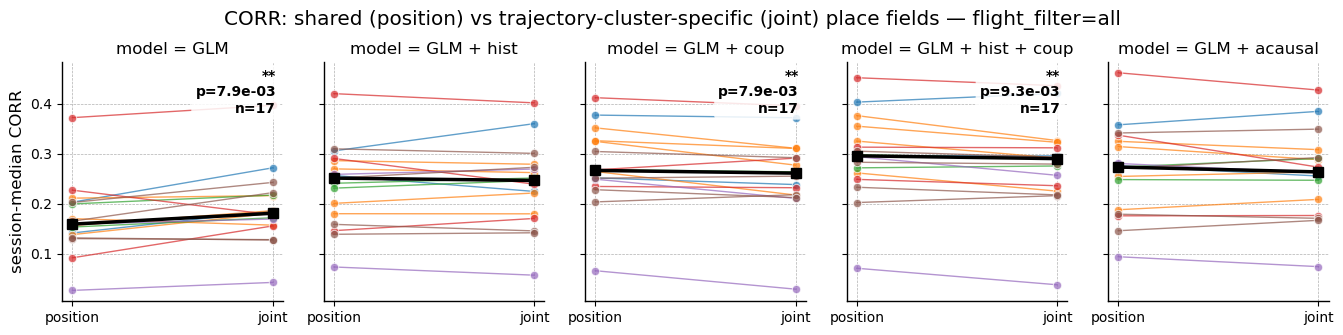

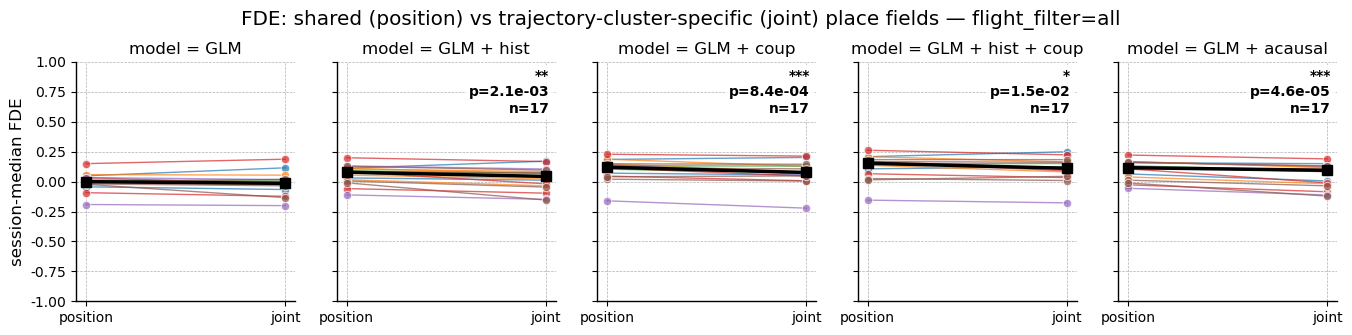

,metric,flight_filter,conditioning,model,n_neurons,neuron_median
0,corr,all,position,GLM,3080,0.150508
1,corr,all,position,GLM + hist,3080,0.210707
2,corr,all,position,GLM + coup,3080,0.256880
3,corr,all,position,GLM + hist + coup,3080,0.274478
4,corr,all,position,GLM + acausal,3080,0.238627
5,corr,all,joint,GLM,3080,0.166293
6,corr,all,joint,GLM + hist,3080,0.212967
7,corr,all,joint,GLM + coup,3080,0.238028
8,corr,all,joint,GLM + hist + coup,3080,0.255562
9,corr,all,joint,GLM + acausal,3080,0.234487


In [53]:
# Shared place fields ("position") vs trajectory-cluster-specific place fields
# ("joint") for each GLM with an explicit position basis. Paired per session
# (one line per session, colored by bat), with the cross-session median in black
# and a session-level Wilcoxon p (joint - position) per panel. FDE axis clipped
# to [-1, 1] (raw values kept for the stats).
cond_sess = (df[df['model'].isin(GLM_JOINT_MODELS)]
             .groupby(['metric', 'flight_filter', 'conditioning', 'session', 'bat', 'model'],
                      observed=True)
             .agg(score=('score', 'median')).reset_index())
cond_sess['model'] = pd.Categorical(cond_sess['model'], categories=GLM_JOINT_MODELS, ordered=True)

for metric in ['corr', 'fde']:
    sub = cond_sess[(cond_sess['metric'] == metric) & (cond_sess['flight_filter'] == 'all')]
    g = sns.FacetGrid(sub, col='model', col_order=GLM_JOINT_MODELS,
                      height=3.4, aspect=0.8, sharey=True)
    g.map_dataframe(
        sns.lineplot, x='conditioning', y='score', units='session',
        hue='bat', palette=BAT_PALETTE, hue_order=list(BAT_PALETTE.keys()),
        estimator=None, marker='o', alpha=0.7, linewidth=1, legend=False)
    for mdl, ax in g.axes_dict.items():
        s2 = sub[sub['model'] == mdl]
        med = (s2.groupby('conditioning', observed=True)['score'].median()
                 .reindex(CONDITIONINGS))
        ax.plot(range(len(med)), med.values, 'ks-', lw=2.5, ms=7, zorder=5)
        pv = s2.pivot_table(index='session', columns='conditioning',
                            values='score', observed=False)
        if {'position', 'joint'} <= set(pv.columns):
            paired = pv[['position', 'joint']].dropna()
            if len(paired) >= 3:
                _, p = wilcoxon_safe((paired['joint'] - paired['position']).values)
                annotate_pvalue_corner(ax, p, n=len(paired))
        if metric == 'fde':
            ax.set_ylim(-1, 1)
    g.set_axis_labels('', f'session-median {metric.upper()}')
    g.figure.suptitle(f'{metric.upper()}: shared (position) vs trajectory-cluster-specific '
                      f'(joint) place fields — flight_filter=all', y=1.04)
    plt.show()

# Summary with SEPARATE ROWS for position vs joint conditioning (all flight filters).
cond_summary = (df[df['model'].isin(GLM_JOINT_MODELS)]
                .groupby(['metric', 'flight_filter', 'conditioning', 'model'], observed=True)
                .agg(n_neurons=('score', 'size'),
                     neuron_median=('score', 'median'))
                .reset_index())
cond_summary[cond_summary['flight_filter'] == 'all']
